# Opdracht : Voorspel herseninfarct


## Teamgegevens

* **teamnaam in kaggle:** 
* **Teamleden met kaggle gebruikersnamen:**
  * Jakub Rebelski (jakubrebelski1)
  * Arda Bagci (Muhammed Arda Bağcı)
  * Vito van Herwerden (Vito van Herwerden)



## Inleiding

In dit project treden wij op als junior data scientists voor MedPredict, een medisch technologiebedrijf dat zorginstellingen ondersteunt bij het vroegtijdig signaleren van gezondheidsrisico’s. Ons doel is om een machine-learningmodel te ontwikkelen dat betrouwbaar voorspelt of een patiënt een verhoogd risico loopt op een herseninfarct (stroke), gebaseerd op geanonimiseerde persoons-, leefstijl- en medische gegevens.

Een sterk voorspellend model kan zorgprofessionals gericht helpen bij preventie en patiëntopvolging. Omdat dit een medische toepassing betreft waarbij verkeerde voorspellingen (zoals onterecht alarm of juist het missen van een risicopatiënt) directe gevolgen hebben, vereist deze opdracht een uiterst kritische blik op de data, de gemaakte keuzes en de uiteindelijke betrouwbaarheid van het model.

Dit project vormt tevens onze inzending voor de Kaggle-competitie van de opleiding Applied Data Science & AI. In dit notebook documenteren we ons volledige proces: van de initiële Exploratieve Data Analyse (EDA) tot het trainen, evalueren en verantwoorden van ons best presterende model.

## Imports
Hier laden we alle benodigde Python-bibliotheken in die we gebruiken voor de data-analyse en het trainen van de modellen die we later nodig gaan hebben.

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

from sklearn.metrics import f1_score, classification_report, confusion_matrix



# Data inladen
Voor dit project maken we gebruik van drie bestanden die voor de Kaggle-competitie beschikbaar zijn gesteld. We laden deze direct aan het begin in:

* **`train_ml.csv`**: De trainingsdataset. Deze bevat de patiëntgegevens inclusief de doelvariabele (wel of geen herseninfarct). We gebruiken deze data voor de Exploratieve Data Analyse (EDA) en om de modellen te trainen.
* **`test_ml.csv`**: De testdataset. Deze bevat dezelfde patiëntgegevens, maar zónder de uitkomst. Ons uiteindelijke model gaat voor deze groep patiënten de voorspellingen maken.
* **`sample_submission.csv`**: Een voorbeeldbestand dat exact het format toont waarin we onze definitieve voorspellingen op Kaggle moeten indienen.

In [2]:
df = pd.read_csv('train_ml.csv')
df_test = pd.read_csv('test_ml.csv')
df_submission = pd.read_csv('sample_submission.csv')

# Hier controleren we of de data correct is ingeladen
df.head()

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,gender_Female,gender_Male,gender_Other,ever_married_No,...,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Rural,Residence_type_Urban,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes,stroke
0,52709,30.0,0,0,63.60,33.3,False,True,False,True,...,False,True,False,False,True,False,False,False,True,0
1,72295,75.0,1,0,215.17,48.0,True,False,False,False,...,False,False,True,False,True,False,False,True,False,0
2,26451,15.0,0,0,135.22,19.0,False,True,False,True,...,False,True,False,False,True,False,False,True,False,0
3,65210,47.0,0,0,64.89,28.2,False,True,False,False,...,False,False,True,False,False,True,False,True,False,0
4,69299,49.0,0,0,222.34,28.8,False,True,False,False,...,False,False,True,False,True,False,True,False,False,0


# 1. Opdracht 1: Exploratieve Data Analyse

De dataset bevat patiëntgegevens waarbij categorische variabelen (zoals geslacht en soort werk) al zijn omgezet in *dummy-variabelen*. Hierbij wordt een tekstwaarde opgesplitst in meerdere kolommen met een 1 (ja) of een 0 (nee), omdat machine learning modellen uitsluitend met numerieke data kunnen rekenen. Hieronder volgt de verklaring van alle 22 kolommen:

## 1.1 Uitleg van colommen

In [3]:
# Hier kijken we welke colommen er in de dataset zitten
list(df.columns)

['id',
 'age',
 'hypertension',
 'heart_disease',
 'avg_glucose_level',
 'bmi',
 'gender_Female',
 'gender_Male',
 'gender_Other',
 'ever_married_No',
 'ever_married_Yes',
 'work_type_Govt_job',
 'work_type_Never_worked',
 'work_type_Private',
 'work_type_Self-employed',
 'work_type_children',
 'Residence_type_Rural',
 'Residence_type_Urban',
 'smoking_status_formerly smoked',
 'smoking_status_never smoked',
 'smoking_status_smokes',
 'stroke']

De dataset bevat patiëntgegevens waarbij categorische variabelen (zoals geslacht en soort werk) al zijn omgezet in *dummy-variabelen*. Hierbij wordt een tekstwaarde opgesplitst in meerdere kolommen met een 1 (ja) of een 0 (nee), omdat machine learning modellen uitsluitend met numerieke data kunnen rekenen. Hieronder volgt de uitleg van alle 22 kolommen:

| Kolomnaam | Uitleg | Type Variabele |
| :--- | :--- | :--- |
| **id** | Unieke identificatiecode van de patiënt. | Identificatie |
| **age** | De leeftijd van de patiënt in jaren. | Numeriek |
| **hypertension** | Geeft aan of de patiënt een hoge bloeddruk heeft (0 = nee, 1 = ja). | Binair |
| **heart_disease** | Geeft aan of de patiënt een hartaandoening heeft (0 = nee, 1 = ja). | Binair |
| **avg_glucose_level** | De gemiddelde suikerspiegel in het bloed van de patiënt. | Numeriek |
| **bmi** | Body Mass Index, een maat voor de verhouding tussen gewicht en lengte. | Numeriek |
| **gender_Female** | Dummy: Patiënt is vrouw (0 = nee, 1 = ja). | Dummy |
| **gender_Male** | Dummy: Patiënt is man (0 = nee, 1 = ja). | Dummy |
| **gender_Other** | Dummy: Patiënt heeft een ander geslacht (0 = nee, 1 = ja). | Dummy |
| **ever_married_No** | Dummy: Patiënt is nooit getrouwd geweest. | Dummy |
| **ever_married_Yes** | Dummy: Patiënt is ooit getrouwd (geweest). | Dummy |
| **work_type_Govt_job** | Dummy: Patiënt werkt voor de overheid. | Dummy |
| **work_type_Never_worked** | Dummy: Patiënt heeft nooit betaald werk gehad. | Dummy |
| **work_type_Private** | Dummy: Patiënt werkt in de private sector. | Dummy |
| **work_type_Self-employed**| Dummy: Patiënt werkt als zelfstandige / ondernemer. | Dummy |
| **work_type_children** | Dummy: Patiënt valt onder de leeftijdscategorie 'kind'. | Dummy |
| **Residence_type_Rural** | Dummy: Patiënt woont op het platteland (rural). | Dummy |
| **Residence_type_Urban** | Dummy: Patiënt woont in een stedelijk gebied (urban). | Dummy |
| **smoking_status_formerly smoked** | Dummy: Patiënt heeft in het verleden gerookt. | Dummy |
| **smoking_status_never smoked** | Dummy: Patiënt heeft nog nooit gerookt. | Dummy |
| **smoking_status_smokes** | Dummy: Patiënt is een actieve roker. | Dummy |
| **stroke** | **De doelvariabele (target).** Heeft de patiënt een herseninfarct gehad? (0 = nee, 1 = ja). | Binair (Target) |

## 1.2 Vereisten voor Machine Learning met Scikit-Learn
Om modellen te kunnen trainen met Scikit-Learn, moet de dataset aan twee strikte voorwaarden voldoen:
1. **Volledig numeriek:** Scikit-Learn algoritmes kunnen uitsluitend rekenen met getallen (integers of floats), niet met tekst (strings). Doordat de tekstuele categorieën in deze dataset al zijn omgezet naar dummy-variabelen (1 en 0), hebben we hier al een grote stap in gemaakt.
2. **Geen missende waarden (NaN):** De modellen crashen als er lege cellen in de data staan. We moeten dus controleren of de dataset helemaal compleet is, en anders de missende data verwijderen of opvullen (imputeren).

## 1.3 Datatypes, missende waarden en basisstatistieken
Om te onderzoeken in hoeverre onze dataset aan bovenstaande eisen voldoet, schrijven we een zelf-gedefinieerde functie. Dit houdt onze code overzichtelijk en herbruikbaar.

In [4]:
def inspecteer_data(dataset):
    """
    Functie om een overzicht te geven van de datatypes, 
    het aantal missende waarden en de basisstatistieken van een dataset.
    """
    print("--- 1. Datatypes ---")
    # info() print automatisch de datatypes en het aantal niet-lege waarden
    dataset.info()
    
    print("\n--- 2. Aantal missende waarden per kolom ---")
    missende_waarden = dataset.isnull().sum()
    # Toon alleen de kolommen waar daadwerkelijk data ontbreekt
    print(missende_waarden[missende_waarden > 0]) 
    
    print("\n--- 3. Basisstatistieken ---")
    # describe() geeft statistieken zoals gemiddelde, min, max en standaarddeviatie
    return dataset.describe()

# Voer de functie uit op onze trainingsdata
inspecteer_data(df)

--- 1. Datatypes ---
<class 'pandas.DataFrame'>
RangeIndex: 33550 entries, 0 to 33549
Data columns (total 22 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              33550 non-null  int64  
 1   age                             33550 non-null  float64
 2   hypertension                    33550 non-null  int64  
 3   heart_disease                   33550 non-null  int64  
 4   avg_glucose_level               33550 non-null  float64
 5   bmi                             33550 non-null  float64
 6   gender_Female                   33550 non-null  bool   
 7   gender_Male                     33550 non-null  bool   
 8   gender_Other                    33550 non-null  bool   
 9   ever_married_No                 33550 non-null  bool   
 10  ever_married_Yes                33550 non-null  bool   
 11  work_type_Govt_job              33550 non-null  bool   
 12  work_type_Never_worked

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,33550.000000,33550.000000,33550.000000,33550.000000,33550.000000,33550.000000,33550.000000
mean,36746.393353,41.815312,0.088137,0.043040,103.587081,28.601216,0.015410
std,20906.519131,22.477423,0.283498,0.202951,42.127396,7.782248,0.123178
min,1.000000,0.080000,0.000000,0.000000,55.010000,10.100000,0.000000
25%,18763.250000,24.000000,0.000000,0.000000,77.460000,23.300000,0.000000
50%,36862.000000,43.000000,0.000000,0.000000,91.320000,27.700000,0.000000
75%,54757.500000,59.000000,0.000000,0.000000,111.437500,32.800000,0.000000
max,72943.000000,82.000000,1.000000,1.000000,281.590000,97.600000,1.000000


## 1.4 Conclusie inspectie en Data Opschonen
Uit de bovenstaande output blijkt dat de dataset voldoet aan de eisen voor Scikit-Learn: er zijn geen missende waarden en alle kolommen hebben een werkbaar datatype (`int`, `float`, `bool`). 

Tijdens het kritisch bekijken van de data zijn ons echter twee dingen opgevallen die we moeten opschonen:
1. **De `id` kolom:** Deze heeft geen voorspellende waarde. Als we deze in de trainingsdata laten staan, kan het model hier onterecht patronen in proberen te vinden (overfitting). We verwijderen deze kolom voor de training.
2. **De "Dummy Variable Trap":** De data is voorbewerkt met dummy-variabelen, maar dit zorgt voor dubbele informatie (multicollineariteit). Zo is `ever_married_No` het exacte tegenovergestelde van `ever_married_Yes`, en geldt hetzelfde voor het type woonomgeving (`Rural`/`Urban`). Daarnaast zagen we een extreme negatieve correlatie tussen de geslachten. Om te voorkomen dat modellen zoals Logistic Regression wiskundig moeite krijgen met deze dubbele informatie, verwijderen we per categorie één overtollige kolom. We droppen daarom `ever_married_No`, `Residence_type_Rural` en `gender_Female`.

In [5]:
def verwijder_kolommen(dataset, kolommen_om_te_verwijderen):
    """
    Verwijdert een opgegeven lijst met kolommen uit de dataset.
    Checkt met een 'if'-statement of de kolom wel echt in de dataset zit.
    """
    df_clean = dataset.copy()
    
    for kolom in kolommen_om_te_verwijderen:
        # Check eerst of de kolom in de dataset bestaat
        if kolom in df_clean.columns:
            df_clean = df_clean.drop(columns=[kolom])
            print(f" Kolom verwijderd: {kolom}")
        else:
            print(f"Let op: Kolom '{kolom}' was al verwijderd of bestaat niet.")
            
    return df_clean

# 1. Bepaal zelf welke kolommen weg moeten
overbodige_kolommen = ['id', 'ever_married_No', 'Residence_type_Rural','gender_Female']

# 2. Roep de herbruikbare functie aan op de trainingsdata
df = verwijder_kolommen(df, overbodige_kolommen)

 Kolom verwijderd: id
 Kolom verwijderd: ever_married_No
 Kolom verwijderd: Residence_type_Rural
 Kolom verwijderd: gender_Female


## 1.5 Relaties tussen variabelen en de doelvariabele
Om te begrijpen welke factoren de grootste invloed hebben op het wel of niet krijgen van een herseninfarct (`stroke`), visualiseren we de data. We maken hiervoor gebruik van een zelf-gedefinieerde functie die boxplots genereert. Hiermee kunnen we de verdeling van numerieke variabelen (zoals leeftijd en glucose) vergelijken tussen patiënten mét (1) en zónder (0) herseninfarct.

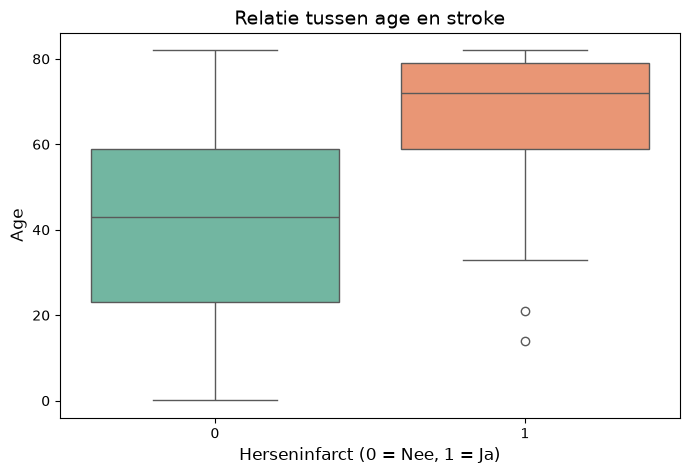

In [6]:
def plot_numeriek_vs_target(dataset, kolom, target='stroke'):
    """
    Genereert een boxplot om de verdeling van een numerieke variabele 
    te vergelijken tussen de twee groepen van de doelvariabele (target).
    """
    plt.figure(figsize=(8, 5))
    
    # Gebruik hue en legend=False om de FutureWarning te voorkomen
    sns.boxplot(data=dataset, x=target, y=kolom, hue=target, palette='Set2', legend=False)
    
    plt.title(f'Relatie tussen {kolom} en {target}', fontsize=14)
    plt.xlabel('Herseninfarct (0 = Nee, 1 = Ja)', fontsize=12)
    plt.ylabel(kolom.capitalize(), fontsize=12)
    
    plt.show()

# Roep de functie aan voor leeftijd (age)
plot_numeriek_vs_target(df, 'age')

### Conclusie: Leeftijd (Age)
Uit de bovenstaande boxplot blijkt dat er een duidelijk verschil in leeftijd is tussen de twee groepen. De patiënten die een herseninfarct hebben gehad (groep 1) zijn gemiddeld aanzienlijk ouder (de mediaan ligt rond de 70 jaar) dan de patiënten zonder herseninfarct (mediaan rond de 43 jaar). Leeftijd lijkt dus een sterke indicatie te geven voor de kans op een herseninfarct.

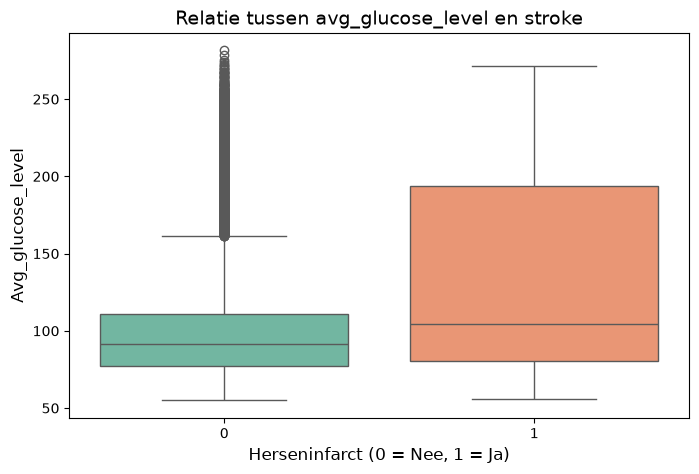

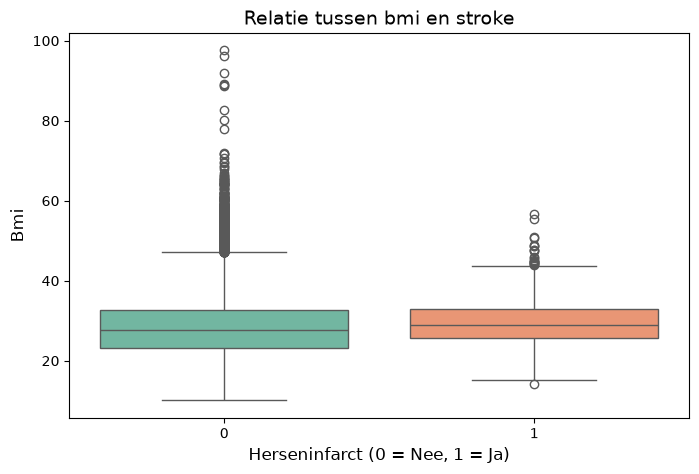

In [7]:
# Analyseer de overige twee numerieke variabelen
plot_numeriek_vs_target(df, 'avg_glucose_level')
plot_numeriek_vs_target(df, 'bmi')

### Conclusie: Gemiddeld Suikerniveau (Avg_glucose_level)
Bij het gemiddelde suikerniveau zien we dat de spreiding in de groep met een herseninfarct (groep 1) veel groter is naar de hogere waarden toe. De mediaan ligt ook iets hoger. Dit suggereert dat hogere glucosewaarden (boven de 100-150) vaker voorkomen bij patiënten die een herseninfarct hebben gehad, wat wijst op een mogelijke relatie.

### Conclusie: Body Mass Index (BMI)
Kijken we naar het BMI, dan zien we nauwelijks verschil tussen de twee groepen. De medianen van beide boxplots liggen vrijwel op dezelfde lijn (rond de 28) en de spreiding van de middelste 50% van de data is nagenoeg identiek. Op basis van deze visuele inspectie lijkt BMI geen erg sterke onderscheidende voorspeller voor een herseninfarct te zijn.

## 1.6 Correlatiematrix (Heatmap)
Om de samenhang tussen alle variabelen te analyseren, berekenen we de correlatiematrix. We tonen specifiek de correlatie van alle kenmerken met de doelvariabele (`stroke`). Dit geeft direct wiskundig inzicht in welke factoren de sterkste positieve of negatieve relatie hebben met het optreden van een herseninfarct

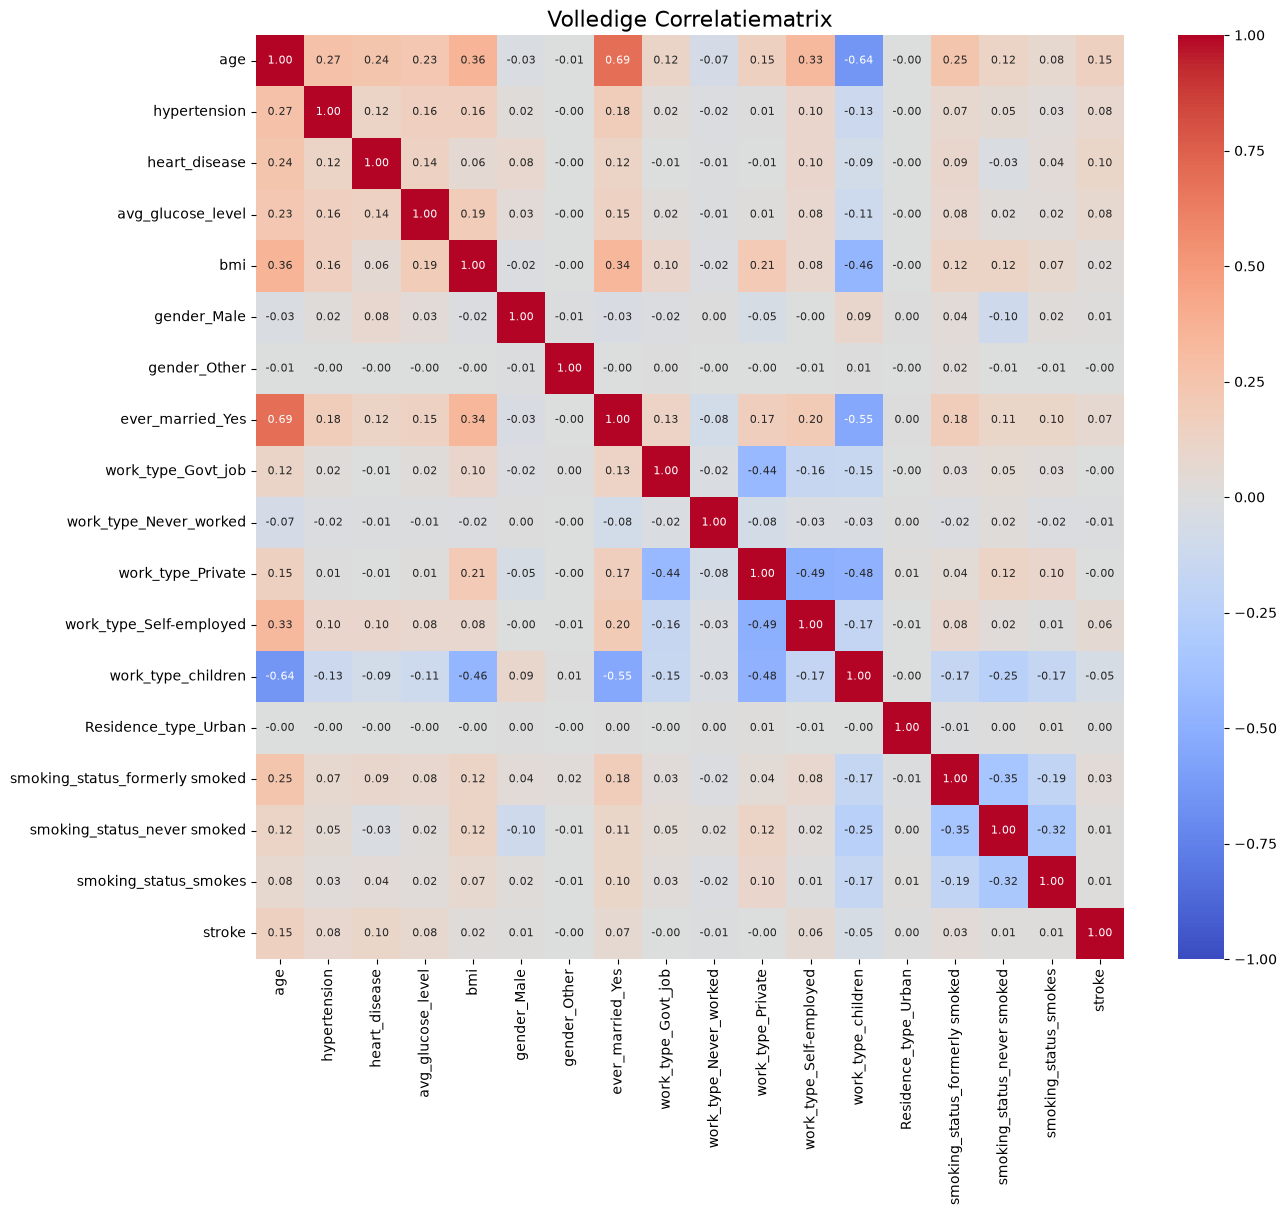

In [8]:
def plot_volledige_correlatiematrix(dataset):
    """
    Berekent de volledige correlatiematrix en genereert een vierkante heatmap 
    van alle variabelen in de dataset.
    """
    correlaties = dataset.corr()
    
    # Maak de grafiek groot genoeg voor alle 20+ kolommen
    plt.figure(figsize=(14, 12))
    
    
    # Genereer de heatmap
    sns.heatmap(correlaties, 
                annot=True,          # Laat de correlatiegetallen zien
                fmt=".2f",           # Twee decimalen
                cmap='coolwarm',     # Rood = positief, Blauw = negatief
                vmin=-1, vmax=1, 
                annot_kws={"size": 8}) # Maak het lettertype iets kleiner voor de leesbaarheid
    
    plt.title('Volledige Correlatiematrix', fontsize=16)
    plt.show()

# Roep de functie aan
plot_volledige_correlatiematrix(df)

### Conclusie: Correlatiematrix (Opgeschoond)
Uit de vernieuwde heatmap komen de volgende belangrijke observaties naar voren:

1. **Beperkte lineaire correlaties met de doelvariabele (`stroke`):** Geen enkele variabele toont een extreem sterke lineaire correlatie met een herseninfarct[cite: 5]. Leeftijd (`age`) heeft de hoogste voorspellende waarde met een correlatie van 0.15[cite: 5]. Daarna volgen hartaandoeningen (`heart_disease`, 0.10), het gemiddelde glucosepeil (`avg_glucose_level`, 0.08) en hoge bloeddruk (`hypertension`, 0.08)[cite: 5]. 
2. **Succesvolle aanpak van Multicollineariteit:** De eerdere extreme correlatie van -1.00 tussen de geslachten is nu volledig verdwenen[cite: 5]. Dit bevestigt dat onze stap om `gender_Female` en de andere overtollige dummy-variabelen te verwijderen, succesvol was in het oplossen van de 'Dummy Variable Trap'. Het model krijgt nu geen dubbele informatie meer.
3. **Natuurlijke verbanden in de data:** Binnen de onafhankelijke variabelen zien we nog wel enkele logische verbanden. Zo is er een sterke positieve correlatie (0.69) tussen leeftijd (`age`) en ooit getrouwd zijn (`ever_married_Yes`)[cite: 5]. Daarnaast is er een sterke negatieve correlatie (-0.64) tussen leeftijd en de werk-categorie kinderen (`work_type_children`)[cite: 5], wat volkomen verklaarbaar is.

## 1.7 Standaardisatie van de data
Machine learning modellen (zoals Logistic Regression en K-Nearest Neighbors) zijn gevoelig voor de schaal van de variabelen. In onze dataset heeft `avg_glucose_level` bijvoorbeeld veel hogere waarden dan `age` of `bmi`. Om te voorkomen dat het model meer waarde hecht aan variabelen puur omdat de getallen groter zijn, passen we standaardisatie toe. 

We gebruiken hiervoor de `StandardScaler` uit Scikit-Learn. Deze transformeert de continue variabelen zodat ze een gemiddelde van 0 en een standaarddeviatie van 1 krijgen. De binaire dummy-variabelen (0 en 1) hoeven we niet te schalen.

In [9]:
def standaardiseer_kolommen(dataset, kolommen):
    """
    Schaalt de opgegeven continue numerieke kolommen met StandardScaler.
    Retourneert de dataset met de aangepaste kolommen.
    """
    df_geschaald = dataset.copy()
    scaler = StandardScaler()
    
    # Pas de scaler alleen toe op de gekozen continue kolommen
    df_geschaald[kolommen] = scaler.fit_transform(df_geschaald[kolommen])
    
    print(f"De volgende kolommen zijn succesvol gestandaardiseerd: {kolommen}")
    return df_geschaald

# 1. Definieer de continue variabelen die op dezelfde schaal moeten komen
te_schalen_kolommen = ['age', 'avg_glucose_level', 'bmi']

# 2. Roep de functie aan om de data aan te passen
df = standaardiseer_kolommen(df, te_schalen_kolommen)

# 3. Laat de eerste 5 rijen zien ter controle
display(df[te_schalen_kolommen].head())

De volgende kolommen zijn succesvol gestandaardiseerd: ['age', 'avg_glucose_level', 'bmi']


,age,avg_glucose_level,bmi
0,-0.525660,-0.949208,0.603791
1,1.476378,2.648741,2.492734
2,-1.193007,0.750898,-1.233751
3,0.230665,-0.918587,-0.051556
4,0.319645,2.818942,0.025544


## 2. Opdracht 2: Evaluatie van het Model

### 2.1 Metrics en de Confusion Matrix

Omdat het voorspellen van een herseninfarct een binair classificatieprobleem is (0 = Nee, 1 = Ja), kunnen we de prestaties van het model beoordelen met behulp van een Confusion Matrix en de daaruit volgende metrics. 

Een Confusion Matrix verdeelt de voorspellingen in vier categorieën:
* **True Positive (TP):** Het model voorspelt een herseninfarct (1) en de patiënt had ook een herseninfarct.
* **True Negative (TN):** Het model voorspelt geen herseninfarct (0) en de patiënt had er ook geen.
* **False Positive (FP):** Het model voorspelt een herseninfarct (1), maar de patiënt had er geen.
* **False Negative (FN):** Het model voorspelt geen herseninfarct (0), maar de patiënt had er wel een.

Op basis van deze vier waarden berekenen we de volgende metrics:
* **Accuracy (Nauwkeurigheid):** Het percentage correcte voorspellingen van het totaal. 
  *Berekening: (TP + TN) / (TP + TN + FP + FN)*
* **Precision (Precisie):** Van alle keren dat het model 'Ja' (1) voorspelde, hoeveel waren er daadwerkelijk 'Ja'?
  *Berekening: TP / (TP + FP)*
* **Recall (Gevoeligheid):** Van alle patiënten die daadwerkelijk een herseninfarct hadden, hoeveel heeft het model er correct gevonden?
  *Berekening: TP / (TP + FN)*
* **F1-score:** Het harmonisch gemiddelde tussen Precision en Recall.
  *Berekening: 2 * (Precision * Recall) / (Precision + Recall)*

### 2.2 Waarom is de F1-score de beste maatstaf voor dit vraagstuk?
In medische datasets zoals deze is de data sterk uit balans (imbalanced). Veruit de meeste patiënten in de dataset hebben geen herseninfarct gehad (klasse 0), en slechts een heel klein percentage wel (klasse 1). 

Als een model simpelweg bij iedereen voorspelt dat ze géén herseninfarct krijgen, is de Accuracy heel hoog, omdat het model het bij de grote groep mensen zonder infarct altijd goed heeft. Het model is in werkelijkheid niet zo goed, want het mist elke daadwerkelijke patiënt (0% Recall voor klasse 1).

De F1-score voorkomt dit door te focussen op de balans tussen Precision en Recall voor de positieve klasse. Om een hoge F1-score te halen, móét het model de daadwerkelijke herseninfarcten (de 1'tjes) goed kunnen identificeren, zonder daarbij veel false positives te genereren. Daarom is de F1-score op Kaggle en in dit onderzoek de meest betrouwbare metric.

### 2.3 Model Training en Uitkomsten
Om de besproken metrics in de praktijk te berekenen, splitsen we de gestandaardiseerde data in een train- en testset. We trainen een Logistic Regression model en genereren vervolgens de Confusion Matrix en het overzicht met de Accuracy, Precision, Recall en F1-score.

In [10]:
# 1. Definieer de onafhankelijke variabelen (X) en de doelvariabele (y)
X = df.drop(columns=['stroke'])
y = df['stroke']

# 2. Splits de data in een train- en testset (80% train, 20% test)
# stratify=y zorgt ervoor dat de verhouding 0/1 in beide sets gelijk blijft
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 3. Kies en train een machine learning algoritme (Logistic Regression)
model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train, y_train)

# 4. Maak voorspellingen op de testset
y_pred = model.predict(X_test)

# 5. Evalueer de uitkomsten met een Confusion Matrix en de metrics
print("Confusion Matrix:")
cm = confusion_matrix(y_test, y_pred)
cm_df = pd.DataFrame(cm, 
                     index=['Werkelijk: 0', 'Werkelijk: 1'], 
                     columns=['Voorspeld: 0', 'Voorspeld: 1'])
display(cm_df)

print("\nClassification Report (inclusief Accuracy, Precision, Recall en F1-score):")
print(classification_report(y_test, y_pred, zero_division=0))

Confusion Matrix:


,Voorspeld: 0,Voorspeld: 1
Werkelijk: 0,6607,0
Werkelijk: 1,103,0



Classification Report (inclusief Accuracy, Precision, Recall en F1-score):
              precision    recall  f1-score   support

           0       0.98      1.00      0.99      6607
           1       0.00      0.00      0.00       103

    accuracy                           0.98      6710
   macro avg       0.49      0.50      0.50      6710
weighted avg       0.97      0.98      0.98      6710



### 2.4 Conclusie Model Evaluatie
De uitkomsten van het Logistic Regression model bevestigen de theorie over ongebalanceerde data perfect. 

Uit de Confusion Matrix blijkt dat het model altijd voorspelt dat een patiënt geen herseninfarct krijgt. Van de 103 patiënten in de testset die daadwerkelijk een infarct kregen (Werkelijk: 1), heeft het model er 0 correct geïdentificeerd. Al deze gevallen zijn geclassificeerd als False Negatives.

Vanwege de grote oververtegenwoordiging van klasse 0 (6607 patiënten) behaalt het model een indrukwekkend lijkende Accuracy van 98%. Echter, het Classification Report toont aan dat de Recall en de F1-score voor klasse 1 (herseninfarct) exact 0.00 zijn. 

Dit bewijst dat Accuracy een misleidende metric is voor dit vraagstuk. De lage F1-score laat eerlijk zien dat het huidige model niet in staat is om voorspellende patronen voor een herseninfarct te herkennen in de data.

## 3. Opdracht 3: Modelleren en Uitleg Modellen

### 3.1 Imbalanced Dataset
Onze dataset is een imbalanced dataset. Bijna iedereen in de data valt in klasse 0 (geen herseninfarct) en maar een heel klein deel valt in klasse 1 (wel een herseninfarct). 
Als we een model hier direct op trainen, is de makkelijkste manier voor het model om een hoge accuracy te halen, dus altijd gewoon 0 voorspellen. Het model leert dan geen echte patronen herkennen, waardoor de voorspellingen voor klasse 1 heel slecht zullen zijn. Om te zorgen dat de modellen deze kleine groep patiënten met een infarct wel goed kunnen voorspellen, gebruiken we per model een bepaalde techniek. Welke techniek dat is en hoe deze werkt, leggen we telkens per model uit.

### 3.2 K-Nearest Neighbors (KNN)

**Aanpak imbalanced data: SMOTE**

Voor dit model gebruiken we de techniek SMOTE (Synthetic Minority Over-sampling Technique). KNN berekent afstanden tussen punten en heeft geen ingebouwde functie om foute voorspellingen zwaarder af te straffen. Daarom moeten we de data zelf in balans brengen. SMOTE doet dit door extra, synthetische datapunten aan te maken voor de minderheidsklasse. Het pakt een datapunt uit klasse 1, kijkt naar de dichtstbijzijnde buren, en plaatst willekeurig nieuwe punten op de lijnen hiertussen. Zo krijgt het model opeens genoeg voorbeelden om van te leren.

We gebruiken hier in de code ook een pipeline voor. Omdat we Cross-Validation gebruiken, wordt de trainingsdata op de achtergrond in 5 kleine stukjes (folds) gehakt. Vier om te trainen en één als test. Als we SMOTE vooraf op alle data zouden toepassen, maakt hij ook nieuwe patiënten aan op basis van dat interne teststukje. Het model kan dan tijdens het trainen stiekem al spieken van de indormatie uit de data waarop hij zo meteen getest wordt (data leakage). Een pipeline voorkomt dit. Een pipeline die splitst de data eerst op en past SMOTE daarna alleen toe op de 4 stukjes waarmee daadwerkelijk getraind wordt.

**Hoe werkt het model?**
KNN kijkt simpelweg naar de patiënten in de dataset met eigenschappen die het meest op een nieuwe patiënt lijken. Als de meerderheid van die dichtstbijzijnde punten een infarct had, dan is dat ook de voorspelling voor de nieuwe patiënt. 
Om te bepalen wie op wie lijkt, berekent KNN de afstand tussen punten in de data. Dit kan op twee manieren:
* **Euclidean afstand:** De kortste afstand in een rechte lijn, zoals je meet met een liniaal.
* **Manhattan afstand:** De afstand gemeten in horizontale en verticale stappen, alsof je in blokken door een stad loopt.

**Waarom is standaardisatie belangrijk voor KNN?**
Omdat KNN puur afstanden berekent, moeten alle variabelen op dezelfde schaal staan (wat we in stap 1.7 al hebben gedaan). Glucosewaarden lopen op tot 300, terwijl leeftijd stopt rond de 80. Zonder standaardisatie zou de afstandsberekening vooral naar glucose kijken, simpelweg omdat dat getal groter is.

**Regularisatie bij KNN**
Bij KNN heb je geen ingewikkelde formule met strafpunten om het model in toom te houden. Je regelt dit gewoon door het aantal buren aan te passen. Als je het model naar maar 1 buur laat kijken, neemt het alle kleine toevalligheden en ruis in de data te letterlijk over (overfitting). Als je meer buren kiest, zoals 5 of 9, moet het model naar het grotere plaatje kijken. Kleine foutjes in de data vallen dan weg. Zo voorkom je overfitting, en dat is eigenlijk hoe regularisatie bij dit model werkt.

In [11]:
# 1. We maken een pipeline, zodat het model niet spiekt.
knn_pipeline = Pipeline([
    ('smote', SMOTE(random_state=42)),
    ('knn', KNeighborsClassifier())
])

# 2. De hyperparameters die we willen proberen 
param_grid_knn = {
    'knn__n_neighbors': [3, 5, 7, 9, 11, 15],
    'knn__metric': ['euclidean', 'manhattan'],
    'knn__weights': ['uniform', 'distance']
}

# 3. Cross-validation instellen. We kijken specifiek naar de f1-score.
grid_knn = GridSearchCV(knn_pipeline, param_grid_knn, cv=5, scoring='f1')

# 4. Model trainen
print("Bezig met trainen en hyperparameter tuning voor KNN...")
grid_knn.fit(X_train, y_train)

# 5. Uitkomsten printen
print("\nBeste hyperparameters voor KNN:", grid_knn.best_params_)
print("Beste F1-score uit cross-validation:", round(grid_knn.best_score_, 4))

Bezig met trainen en hyperparameter tuning voor KNN...

Beste hyperparameters voor KNN: {'knn__metric': 'manhattan', 'knn__n_neighbors': 15, 'knn__weights': 'distance'}
Beste F1-score uit cross-validation: 0.0823


### **Resultaat van KNN**
Uit de GridSearchCV blijken de volgende hyperparameters de beste resultaten te geven: 
* Aantal buren (n_neighbors): 15
* Afstandsmeting (metric): Manhattan
* Weging (weights): distance

Met deze instellingen en het gebruik van SMOTE behaalt het KNN-model een F1-score van 0.0823.

## 3.3 Logistic Regression

### Werking van Logistic Regression

Logistic Regression is een binair classificatiemodel. Het model berekent eerst een lineaire score op basis van de kenmerken van een patiënt:

$$z = \beta_0 + \beta_1x_1 + \beta_2x_2 + \dots + \beta_px_p$$

Deze score wordt omgezet naar een kans tussen 0 en 1 met de sigmoidfunctie:

$$\hat{p}(y=1\mid x)=\sigma(z)=\frac{1}{1+e^{-z}}$$

waarbij:

- $\beta_0$ de intercept is;
- $\beta_1,\dots,\beta_p$ de gewichten van de kenmerken zijn;
- $x_1,\dots,x_p$ de kenmerken van een patiënt zijn;
- $\hat{p}$ de voorspelde kans op een herseninfarct is.

Bij een beslisdrempel van 0,5 voorspelt het model klasse 1 wanneer $\hat{p}\geq0,5$ en klasse 0 wanneer $\hat{p}<0,5$. Omdat de dataset sterk imbalanced is, gebruiken we tijdens de optimalisatie een lagere beslisdrempel. Daardoor worden meer patiënten met een verhoogd risico geselecteerd en wordt het aantal False Negatives beperkt.

### Imbalanced data

In onze dataset heeft slechts ongeveer 1,54% van de patiënten een herseninfarct gehad. Klasse 0 is daardoor sterk oververtegenwoordigd. Zonder extra maatregelen kan Logistic Regression een hoge accuracy behalen door bijna altijd klasse 0 te voorspellen, terwijl de recall en F1-score voor klasse 1 zeer laag blijven.

Voor dit model vergelijken we twee technieken:

1. **SMOTE:** maakt synthetische voorbeelden van de minderheidsklasse door punten te construeren tussen bestaande positieve voorbeelden en hun dichtstbijzijnde buren. SMOTE wordt binnen de pipeline toegepast, zodat de validatiefolds niet worden gebruikt om kunstmatige trainingsvoorbeelden te maken. Hierdoor voorkomen we data leakage.
2. **Class weighting:** geeft fouten op klasse 1 een groter gewicht. Met `class_weight='balanced'` worden de gewichten automatisch omgekeerd evenredig aan de klassengrootte gekozen.

We laten GridSearchCV beide technieken vergelijken. Per combinatie wordt óf SMOTE gebruikt óf class weighting. Zo onderzoeken we welke aanpak op de gekozen metric het beste werkt.

### Loss-functie

Logistic Regression gebruikt log loss, ook wel binary cross-entropy genoemd:

$$
J(\beta)=-\frac{1}{n}\sum_{i=1}^{n}\left[y_i\log(\hat{p}_i)+(1-y_i)\log(1-\hat{p}_i)\right]
$$

Voor één observatie geldt:

- als $y_i=1$, wordt de term $-\log(\hat{p}_i)$ gebruikt;
- als $y_i=0$, wordt de term $-\log(1-\hat{p}_i)$ gebruikt.

Een correcte voorspelling met hoge zekerheid geeft een kleine loss. Een foute voorspelling met hoge zekerheid geeft juist een grote loss. Hierdoor wordt het model sterk gestraft wanneer het een patiënt met een herseninfarct een zeer lage kans geeft.

### Gradient descent

Gradient descent zoekt de gewichten die de loss zo klein mogelijk maken. De gradiënt geeft aan in welke richting de loss het sterkst toeneemt. Daarom bewegen we in de tegengestelde richting:

$$
\beta_j^{nieuw}=\beta_j^{oud}-\eta\frac{\partial J}{\partial\beta_j}
$$

Hierbij is $\eta$ de learning rate.

Een eenvoudig voorbeeld: stel dat een model voor één patiënt $\hat{p}=0,40$ voorspelt, terwijl de werkelijke klasse $y=1$ is. De fout is:

$$
\hat{p}-y=0,40-1=-0,60
$$

Als de leeftijd $x=2$ is, dan is de afgeleide voor het gewicht bij leeftijd:

$$
\frac{\partial J}{\partial\beta_{age}}=(\hat{p}-y)x=-0,60\times2=-1,20
$$

Bij een learning rate van $\eta=0,1$ wordt het gewicht:

$$
\beta_{age}^{nieuw}=\beta_{age}^{oud}-0,1(-1,20)=\beta_{age}^{oud}+0,12
$$

Het gewicht van leeftijd wordt dus groter. Daardoor zal het model bij vergelijkbare oudere patiënten in de volgende iteratie een hogere kans op klasse 1 berekenen.

### Regularisatie

Regularisatie voegt een strafterm toe aan de loss-functie. Hierdoor worden extreem grote gewichten ontmoedigd en wordt overfitting verminderd.

**L2-regularisatie (Ridge):**

$$
J_{L2}=J(\beta)+\lambda\sum_{j=1}^{p}\beta_j^2
$$

L2 maakt grote gewichten kleiner, maar meestal niet exact nul. In Scikit-Learn wordt de sterkte geregeld met $C$:

$$
C=\frac{1}{\lambda}
$$

Een kleine $C$ betekent sterke regularisatie; een grote $C$ betekent zwakke regularisatie.

**L1-regularisatie (Lasso):**

$$
J_{L1}=J(\beta)+\lambda\sum_{j=1}^{p}|\beta_j|
$$

L1 kan gewichten exact op nul zetten. Daardoor werkt L1 ook als methode voor feature selection.

**Elastic Net:**

$$
J_{EN}=J(\beta)+\lambda\left[\alpha\sum_{j=1}^{p}|\beta_j|+(1-\alpha)\sum_{j=1}^{p}\beta_j^2\right]
$$

Elastic Net combineert L1 en L2. In Scikit-Learn is hiervoor de solver `saga` nodig.

Regularisatie vermindert overfitting doordat het model minder flexibel wordt. Bij te sterke regularisatie kunnen belangrijke patronen echter verdwijnen. Dan ontstaat underfitting. Daarom zoeken we de beste waarde van $C$ met cross-validation.


In [59]:
### Imports

from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    f1_score, precision_score, recall_score, accuracy_score,
    classification_report, confusion_matrix, make_scorer
)
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from sklearn.base import BaseEstimator, TransformerMixin


In [60]:
### Voorbereiding zonder data leakage
# Lees de oorspronkelijke bestanden opnieuw in, zodat train en test dezelfde
# preprocessing krijgen en de originele testdata behouden blijft.
df_train_raw = pd.read_csv('train_ml.csv')
df_test_raw = pd.read_csv('test_ml.csv')

kolommen_verwijderen = [
    'id',
    'ever_married_No',
    'Residence_type_Rural',
    'gender_Female'
]

X_full = df_train_raw.drop(columns=['stroke'] + kolommen_verwijderen).astype(float)
y_full = df_train_raw['stroke'].astype(int)
X_kaggle = df_test_raw.drop(columns=kolommen_verwijderen).astype(float)

X_train_lr, X_valid_lr, y_train_lr, y_valid_lr = train_test_split(
    X_full,
    y_full,
    test_size=0.20,
    random_state=42,
    stratify=y_full
)

print('Trainverdeling:')
print(y_train_lr.value_counts(normalize=True))
print('\nValidatieverdeling:')
print(y_valid_lr.value_counts(normalize=True))

Trainverdeling:
stroke
0    0.984575
1    0.015425
Name: proportion, dtype: float64

Validatieverdeling:
stroke
0    0.98465
1    0.01535
Name: proportion, dtype: float64


In [61]:


### Cross-validation en hyperparameter tuning

f1_positief = make_scorer(f1_score, pos_label=1, zero_division=0)

logistic_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('smote', SMOTE(random_state=42)),
    ('logistic', LogisticRegression(max_iter=3000, random_state=42))
])

param_grid_logistic = [
    {
        'smote': [SMOTE(random_state=42)],
        'logistic__penalty': ['l2'],
        'logistic__solver': ['lbfgs'],
        'logistic__C': [0.01, 0.1, 1, 10, 100],
        'logistic__class_weight': [None]
    },
    {
        'smote': ['passthrough'],
        'logistic__penalty': ['l2'],
        'logistic__solver': ['lbfgs'],
        'logistic__C': [0.01, 0.1, 1, 10, 100],
        'logistic__class_weight': [None, 'balanced']
    },
    {
        'smote': ['passthrough'],
        'logistic__penalty': ['l1', 'l2'],
        'logistic__solver': ['saga'],
        'logistic__C': [0.01, 0.1, 1, 10],
        'logistic__class_weight': [None, 'balanced']
    }
]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid_logistic = GridSearchCV(
    estimator=logistic_pipeline,
    param_grid=param_grid_logistic,
    scoring=f1_positief,
    cv=cv,
    n_jobs=-1,
    refit=True,
    return_train_score=True
)

print('Bezig met cross-validation en hyperparameter tuning...')
grid_logistic.fit(X_train_lr, y_train_lr)

print('\nBeste hyperparameters:')
print(grid_logistic.best_params_)
print(f'Beste gemiddelde CV-F1-score: {grid_logistic.best_score_:.4f}')

Bezig met cross-validation en hyperparameter tuning...

Beste hyperparameters:
{'logistic__C': 10, 'logistic__class_weight': None, 'logistic__penalty': 'l2', 'logistic__solver': 'lbfgs', 'smote': SMOTE(random_state=42)}
Beste gemiddelde CV-F1-score: 0.0901


In [64]:


### Resultaten op de validatieset

y_valid_pred_lr = grid_logistic.predict(X_valid_lr)

y_valid_prob_lr = grid_logistic.predict_proba(X_valid_lr)[:, 1]

cm_lr = confusion_matrix(y_valid_lr, y_valid_pred_lr)
cm_lr_df = pd.DataFrame(
    cm_lr,
    index=['Werkelijk: 0', 'Werkelijk: 1'],
    columns=['Voorspeld: 0', 'Voorspeld: 1']
)

display(cm_lr_df)

print(classification_report(
    y_valid_lr,
    y_valid_pred_lr,
    target_names=['Geen herseninfarct', 'Wel herseninfarct'],
    zero_division=0
))

resultaten_logistic = pd.DataFrame({
    'metric': ['accuracy', 'precision_klasse_1', 'recall_klasse_1', 'f1_klasse_1'],
    'score': [
        accuracy_score(y_valid_lr, y_valid_pred_lr),
        precision_score(y_valid_lr, y_valid_pred_lr, zero_division=0),
        recall_score(y_valid_lr, y_valid_pred_lr, zero_division=0),
        f1_score(y_valid_lr, y_valid_pred_lr, zero_division=0)
    ]
})

display(resultaten_logistic)

,Voorspeld: 0,Voorspeld: 1
Werkelijk: 0,4995,1612
Werkelijk: 1,18,85


                    precision    recall  f1-score   support

Geen herseninfarct       1.00      0.76      0.86      6607
 Wel herseninfarct       0.05      0.83      0.09       103

          accuracy                           0.76      6710
         macro avg       0.52      0.79      0.48      6710
      weighted avg       0.98      0.76      0.85      6710



,metric,score
0,accuracy,0.757079
1,precision_klasse_1,0.050088
2,recall_klasse_1,0.825243
3,f1_klasse_1,0.094444


In [63]:


### Optionele optimalisatie van de beslisdrempel

drempels = np.arange(0.10, 0.61, 0.01)
f1_scores_drempel = [
    f1_score(y_valid_lr, (y_valid_prob_lr >= d).astype(int), zero_division=0)
    for d in drempels
]

beste_index = int(np.argmax(f1_scores_drempel))
beste_drempel_lr = float(drempels[beste_index])
beste_f1_drempel_lr = float(f1_scores_drempel[beste_index])

print(f'Beste beslisdrempel: {beste_drempel_lr:.2f}')
print(f'F1-score bij deze drempel: {beste_f1_drempel_lr:.4f}')

Beste beslisdrempel: 0.60
F1-score bij deze drempel: 0.1041


In [62]:
### Trainen op alle trainingsdata en Kaggle-submission maken

beste_model_lr = grid_logistic.best_estimator_
beste_model_lr.fit(X_full, y_full)

# Gebruik dezelfde beslisdrempel die uitsluitend op de validatieset is gekozen.
test_prob_lr = beste_model_lr.predict_proba(X_kaggle)[:, 1]
test_pred_lr = (test_prob_lr >= beste_drempel_lr).astype(int)

submission_lr = df_submission.copy()

# Zoek de targetkolom automatisch. Bij de meeste Kaggle-opdrachten heet deze
# 'stroke'; anders wordt de laatste kolom gebruikt.
if 'stroke' in submission_lr.columns:
    target_submission_kolom = 'stroke'
else:
    target_submission_kolom = submission_lr.columns[-1]

submission_lr[target_submission_kolom] = test_pred_lr
submission_lr.to_csv('submission_logistic_regression.csv', index=False)

print('Submission opgeslagen als: submission_logistic_regression.csv')
print(submission_lr.head())
print('\nAantal voorspelde positieven:', int(test_pred_lr.sum()))


Submission opgeslagen als: submission_logistic_regression.csv
      id  stroke
0  32840       0
1  45158       0
2  56105       0
3   3112       0
4  35224       0

Aantal voorspelde positieven: 1715


In [65]:



### Conclusie Logistic Regression

# Handig overzicht voor in het verslag
print('Samenvatting Logistic Regression')
print('Beste parameters:', grid_logistic.best_params_)
print(f'Beste CV-F1-score: {grid_logistic.best_score_:.4f}')
print(f'Validatie-F1-score bij drempel {beste_drempel_lr:.2f}: {beste_f1_drempel_lr:.4f}')

Samenvatting Logistic Regression
Beste parameters: {'logistic__C': 10, 'logistic__class_weight': None, 'logistic__penalty': 'l2', 'logistic__solver': 'lbfgs', 'smote': SMOTE(random_state=42)}
Beste CV-F1-score: 0.0901
Validatie-F1-score bij drempel 0.60: 0.1041


**Conclusie Logistic Regression**

Logistic Regression is een goed interpreteerbaar basismodel, omdat ieder gewicht de richting en sterkte van de relatie tussen een kenmerk en de kans op een herseninfarct weergeeft. Het oorspronkelijke model voorspelde uitsluitend klasse 0 en behaalde daardoor een misleidende accuracy van 98%, maar een F1-score van 0 voor klasse 1. Door cross-validation, SMOTE of class weighting, standaardisatie, regularisatie en het tunen van $C$, de penalty en de solver kan het model beter omgaan met de imbalanced dataset. Voor deze opdracht kiezen we de combinatie met de hoogste gemiddelde F1-score voor klasse 1 als het beste Logistic Regression-model.

# 3.4 Support Vector Machine (SVM)

## 3.4.1 Waarom SVM geschikt is voor deze opdracht

Een Support Vector Machine (SVM) is een supervised-learningmodel voor classificatie. Het model zoekt een beslissingsgrens die de twee klassen zo goed mogelijk van elkaar scheidt. In dit project zijn de twee klassen:

- `0`: geen Stroke;
- `1`: wel een Stroke.

De dataset is sterk imbalanced: slechts ongeveer **1,54%** van de patiënten heeft `stroke = 1`. Een standaard-SVM kan daardoor vooral leren om klasse 0 te voorspellen. Dat levert een hoge accuracy op, maar een zeer lage recall voor de belangrijke positieve klasse.

Daarom gebruiken we binnen de cross-validation een combinatie van technieken:

1. **SMOTE:** maakt synthetische voorbeelden van de minderheidsklasse binnen uitsluitend de trainingsfold;
2. **class weighting:** geeft fouten op klasse 1 extra gewicht via `class_weight='balanced'`;
3. **F1-score:** wordt gebruikt als optimalisatiemetric, omdat deze precision en recall combineert en daardoor een goede inzagen geeft van hoe goed het model echt voorspeld.

SMOTE en class weighting pakken de onbalans op verschillende manieren aan. SMOTE verandert de verdeling van de trainingsdata, terwijl class weighting de kosten van classificatiefouten aanpast.

> Belangrijk: SMOTE staat in de pipeline. Daardoor wordt SMOTE tijdens iedere cross-validation-fold alleen op het interne trainingsdeel toegepast. Zo voorkomen we data leakage.

---

## 3.4.2 Werking van SVM

SVM probeert een hypervlak te vinden dat de klassen scheidt. Bij twee kenmerken kan dit hypervlak een lijn zijn; bij meer kenmerken is het een vlak of een hypervlak.

De beslissingsfunctie van een lineaire SVM is:

$$
f(x) = w^T x + b
$$

waarbij:

- $$x$$ de kenmerken van een patiënt zijn;
- $$w$$ de gewichten van de kenmerken zijn;
- $$b$$ de bias/intercept is.

De voorspelling wordt bijvoorbeeld gegeven door:

$$
\hat{y} =
\begin{cases}
1 & \text{als } f(x) \geq 0 \\
0 & \text{als } f(x) < 0
\end{cases}
$$

De scheidingsgrens wordt gevonden door de marge tussen beide klassen zo groot mogelijk te maken. De marge wordt bepaald door de zogenaamde **support vectors**. Dit zijn de datapunten die het dichtst bij de beslissingsgrens liggen. Deze punten hebben de grootste invloed op de uiteindelijke grens.

### Eenvoudig rekenvoorbeeld

Stel dat we slechts twee gestandaardiseerde kenmerken gebruiken:

- $$x_1$$ = leeftijd;
- $$x_2$$ = gemiddeld glucosegehalte.

Neem als beslissingsfunctie:

$$
f(x) = 0{,}8x_1 + 0{,}5x_2 - 0{,}4
$$

Voor een patiënt met:

$$
x = (1{,}0, 0{,}6)$$

wordt:

$$
f(x) = 0{,}8(1{,}0) + 0{,}5(0{,}6) - 0{,}4 = 0{,}7
$$

Omdat $$f(x) > 0$$, voorspelt het model klasse 1. Voor een patiënt met:

$$
x = (-0{,}5, -0{,}2)$$

krijgen we:

$$
f(x) = 0{,}8(-0{,}5) + 0{,}5(-0{,}2) - 0{,}4 = -0{,}9
$$

Deze patiënt wordt dus ingedeeld in klasse 0.

De afstand van een punt tot het hypervlak is:

$$
\text{afstand}(x, H) = \frac{|w^T x + b|}{\|w\|}
$$

Een grotere marge betekent doorgaans een robuuster model dat minder gevoelig is voor kleine variaties in de trainingsdata.

---

## 3.4.3 Soft margin en de parameter C

In echte datasets zijn de klassen meestal niet perfect lineair te scheiden. Daarom gebruikt SVM vaak een **soft margin**. Het model staat dan toe dat sommige datapunten aan de verkeerde kant van de grens liggen.

De parameter $$C$$ bepaalt hoe zwaar deze fouten worden bestraft:

- **lage $$C$$:** grotere marge, meer toegestane fouten, sterkere regularisatie;
- **hoge $$C$$:** minder toegestane fouten, kleinere marge, risico op overfitting.

Een lage waarde van $$C$$ maakt het model eenvoudiger. Een hoge waarde probeert de trainingsdata zo goed mogelijk te classificeren, maar kan daardoor ruis en toevalligheden leren.

---

## 3.4.4 Loss-functie: hinge loss

SVM gebruikt de **hinge loss**. Voor één observatie wordt deze geschreven als:

$$
L_{hinge}(y, f(x)) = \max(0, 1 - y f(x))
$$

Hierbij wordt de doelvariabele gecodeerd als:

$$
y \in \{-1, +1\}
$$

De betekenis is:

- als $$y f(x) \geq 1$$, is de classificatie correct én ligt het punt buiten de marge. Dan is de loss 0;
- als $$0 < y f(x) < 1$$, is de classificatie correct, maar ligt het punt binnen de marge. Dan is er een positieve loss;
- als $$y f(x) \leq 0$$, is de classificatie fout. Dan is de loss groter dan 1.

### Voorbeeld van hinge loss

Stel dat de werkelijke klasse $y=+1$ is. De hinge loss wordt berekend met:

$$
L=\max(0,1-yf(x)).
$$

Voorbeelden:

1. Als $f(x)=1{,}5$:

   $$
   L=\max(0,1-1\cdot1{,}5)=0
   $$

   De voorspelling voldoet aan de gewenste marge.

2. Als $f(x)=0{,}4$:

   $$
   L=\max(0,1-0{,}4)=0{,}6
   $$

   De voorspelling is correct, maar ligt binnen de marge.

3. Als $f(x)=-0{,}8$:

   $$
   L=\max(0,1-(-0{,}8))=1{,}8
   $$

   De voorspelling is fout en krijgt daarom een grote straf.

De geoptimaliseerde soft-margin-doelfunctie is:

$$
\min_{w,b,\xi}\frac{1}{2}\|w\|^2+C\sum_{i=1}^{n}\xi_i
$$

onder de voorwaarden:

$$
y_i(w^Tx_i+b)\geq 1-\xi_i,
$$

$$
\xi_i\geq 0.
$$

De eerste term, $\frac{1}{2}\|w\|^2$, beperkt de complexiteit van het model en zorgt voor een zo groot mogelijke marge. De tweede term, $C\sum_{i=1}^{n}\xi_i$, bestraft overtredingen van de marge. De parameter $C$ bepaalt de verhouding tussen modelcomplexiteit en fouten:

- een grote $C$ bestraft fouten zwaar;
- een kleine $C$ staat meer marge-overtredingen toe.

De slackvariabelen $\xi_i$ geven aan in hoeverre een datapunt de marge overtreedt. Bij de hinge loss geldt in feite:

$$
\xi_i=\max(0,1-y_i(w^Tx_i+b)).
$$


## 3.4.5 Regularisatie bij SVM

Regularisatie voorkomt dat een SVM te complex wordt en daardoor overfit.

### L2-regularisatie

De standaardformulering van SVM gebruikt een L2-achtige complexiteitsstraf:

$$
\frac{1}{2}\|w\|^2 = \frac{1}{2}\sum_{j=1}^{p}w_j^2
$$

Grote gewichten worden sterk bestraft. Het model zoekt daardoor een beslissingsgrens met een brede marge.

Effecten:

- minder gevoeligheid voor ruis;
- vaak betere generalisatie;
- gewichten worden kleiner, maar meestal niet exact nul.

### Parameter C als regularisatie-instelling

De waarde van $$C$$ bepaalt indirect hoeveel regularisatie wordt toegepast:

- kleine $$C$$ betekent sterkere regularisatie;
- grote $$C$$ betekent zwakkere regularisatie.

### Kernelregularisatie

Bij niet-lineaire kernels wordt de beslissingsgrens in een hogere-dimensionale ruimte gezocht. De keuze van kernel en parameters zoals $$\gamma$$ bepaalt daarmee ook de complexiteit van het model.

Een te grote $$\gamma$$ zorgt ervoor dat elk individueel datapunt een sterke lokale invloed krijgt. Dat kan tot overfitting leiden. Een kleinere $$\gamma$$ maakt de invloed van ieder datapunt breder en de grens meestal gladder.

---

## 3.4.6 Kernels en de kernel trick

Een lineaire SVM kan alleen een rechte beslissingsgrens vinden. Wanneer de klassen niet lineair scheidbaar zijn, kan een kernel worden gebruikt.

Een kernel berekent de overeenkomst tussen twee datapunten alsof ze naar een hogere-dimensionale ruimte zijn getransformeerd, zonder die transformatie expliciet uit te voeren. Dit heet de **kernel trick**.

### Lineaire kernel

$$
K(x_i,x_j)=x_i^Tx_j
$$

Geschikt wanneer de klassen ongeveer lineair scheidbaar zijn. Deze kernel is meestal snel.

### RBF-kernel

De radial basis function-kernel is:

$$
K(x_i,x_j)=\exp(-\gamma\|x_i-x_j\|^2)
$$

De RBF-kernel kan complexe, niet-lineaire grenzen modelleren.

- hoge $$\gamma$$: alleen zeer nabije punten lijken op elkaar; complexere grens;
- lage $$\gamma$$: ook verder gelegen punten hebben invloed; eenvoudigere grens.

### Polynomial kernel

$$
K(x_i,x_j)=(\gamma x_i^Tx_j+r)^d
$$

waarbij $$d$$ de graad van de polynoom is. Een hogere graad kan complexere relaties modelleren, maar verhoogt ook het risico op overfitting.

In dit project vergelijken we de kernels `linear`, `rbf` en `poly`.

---

## 3.4.7 SVM trainen met een leakage-vrije pipeline

De dataset is in eerdere stappen al opgeschoond. Voor SVM is het belangrijk dat de continue variabelen gestandaardiseerd zijn. In de onderstaande pipeline gebeurt de standaardisatie opnieuw binnen de pipeline. Dat is veiliger wanneer cross-validation wordt gebruikt.

In [ ]:
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    f1_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score
)
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE


In [ ]:
# Verwijder de target uit de kenmerken
X = df.drop(columns=['stroke'])
y = df['stroke']

# Zorg dat bool-kolommen numeriek zijn
X = X.astype(float)

# Continue variabelen die gestandaardiseerd worden
continue_columns = ['age', 'avg_glucose_level', 'bmi']

# Bepaal de kolomindexen binnen X
scale_indices = [X.columns.get_loc(kolom) for kolom in continue_columns]

# SVM-pipeline:
# 1. standaardiseren;
# 2. SMOTE uitsluitend op het interne trainingsdeel;
# 3. class_weight='balanced' in SVC;
# 4. SVM trainen.
svm_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('smote', SMOTE(random_state=42)),
    ('svm', SVC(
        class_weight='balanced',
        random_state=42,
        probability=False
    ))
])

## 3.4.8 Cross-validation en hyperparameter tuning

We gebruiken `StratifiedKFold`, zodat iedere fold ongeveer dezelfde verhouding tussen klasse 0 en klasse 1 bevat. De keuze van de hyperparameters wordt uitsluitend beoordeeld met de F1-score.

In [ ]:
from sklearn.model_selection import StratifiedKFold, GridSearchCV

cv_strategy = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

param_grid_svm = [
    {
        'svm__kernel': ['linear'],
        'svm__C': [0.1, 1, 10]
    },
    {
        'svm__kernel': ['rbf'],
        'svm__C': [0.1, 1, 10],
        'svm__gamma': ['scale', 0.01]
    }
]

grid_svm = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=param_grid_svm,
    scoring='f1',
    cv=cv_strategy,
    n_jobs=2,       # Gebruik niet alle processorkernen
    verbose=1,
    refit=True
)

print("Bezig met trainen en hyperparameter tuning voor SVM...")
grid_svm.fit(X_train.astype(float), y_train)

print("\nBeste hyperparameters voor SVM:")
print(grid_svm.best_params_)
print(f"Beste gemiddelde F1-score: {grid_svm.best_score_:.4f}")

Bezig met trainen en hyperparameter tuning voor SVM...
Fitting 3 folds for each of 9 candidates, totalling 27 fits

Beste hyperparameters voor SVM:
{'svm__C': 0.1, 'svm__kernel': 'linear'}
Beste gemiddelde F1-score: 0.0884


### Interpretatie van de hyperparameters

| Hyperparameter | Betekenis |
|---|---|
| `C` | Bepaalt hoe zwaar marge-overtredingen worden bestraft. |
| `kernel` | Vorm van de beslissingsgrens: lineair, RBF of polynomiaal. |
| `gamma` | Bepaalt bij RBF en polynomial hoe groot de invloed van een datapunt is. |
| `degree` | Graad van de polynomial kernel. |
| `class_weight='balanced'` | Geeft de minderheidsklasse automatisch een hoger gewicht. |

De beste waarden moeten uit de eigen uitvoering van `GridSearchCV` worden overgenomen. Vul de uitkomst dus niet handmatig in, omdat de optimale waarden afhankelijk zijn van de dataset en de gekozen preprocessing.

---

## 3.4.9 Evaluatie van het beste SVM-model

Na de tuning evalueren we het beste model op een afzonderlijke validatieset. Deze validatieset is niet gebruikt om de hyperparameters te bepalen.

In [ ]:
# Voorspellingen met het beste SVM-model
y_pred_svm = grid_svm.best_estimator_.predict(X_test.astype(float))

cm_svm = confusion_matrix(y_test, y_pred_svm)
cm_svm_df = pd.DataFrame(
    cm_svm,
    index=['Werkelijk: 0', 'Werkelijk: 1'],
    columns=['Voorspeld: 0', 'Voorspeld: 1']
)

print('Confusion Matrix - SVM:')
display(cm_svm_df)

print('\nClassification Report - SVM:')
print(classification_report(y_test, y_pred_svm, zero_division=0))

print('Accuracy:', round((y_test == y_pred_svm).mean(), 4))
print('Precision klasse 1:', round(precision_score(y_test, y_pred_svm, zero_division=0), 4))
print('Recall klasse 1:', round(recall_score(y_test, y_pred_svm, zero_division=0), 4))
print('F1-score klasse 1:', round(f1_score(y_test, y_pred_svm, zero_division=0), 4))

Confusion Matrix - SVM:


,Voorspeld: 0,Voorspeld: 1
Werkelijk: 0,4950,1657
Werkelijk: 1,18,85



Classification Report - SVM:
              precision    recall  f1-score   support

           0       1.00      0.75      0.86      6607
           1       0.05      0.83      0.09       103

    accuracy                           0.75      6710
   macro avg       0.52      0.79      0.47      6710
weighted avg       0.98      0.75      0.84      6710

Accuracy: 0.7504
Precision klasse 1: 0.0488
Recall klasse 1: 0.8252
F1-score klasse 1: 0.0921


## 3.4.10 Optioneel: de beslisdrempel aanpassen

Een standaard-SVM voorspelt klasse 1 wanneer de decision score positief is. In een medische toepassing kan het nuttig zijn om meer patiënten met risico te vinden. Daarom kan de beslisdrempel worden aangepast.

Een lagere drempel verhoogt meestal de recall, maar kan ook meer false positives veroorzaken. De optimale drempel moet daarom uitsluitend op een aparte validatieset worden bepaald.

In [ ]:
# Decision scores voor de positieve klasse
svm_scores = grid_svm.best_estimator_.decision_function(X_test.astype(float))

threshold_results = []
for threshold in np.arange(-1.5, 1.51, 0.1):
    y_pred_threshold = (svm_scores >= threshold).astype(int)
    threshold_results.append({
        'threshold': threshold,
        'precision': precision_score(y_test, y_pred_threshold, zero_division=0),
        'recall': recall_score(y_test, y_pred_threshold, zero_division=0),
        'f1': f1_score(y_test, y_pred_threshold, zero_division=0)
    })

threshold_df = pd.DataFrame(threshold_results)
beste_threshold = threshold_df.loc[threshold_df['f1'].idxmax()]

print('Beste beslisdrempel op de validatieset:')
display(beste_threshold.to_frame().T)

Beste beslisdrempel op de validatieset:


,threshold,precision,recall,f1
23,0.8,0.071174,0.582524,0.12685


 ## 3.4.11 SVM trainen op alle trainingsdata

Nadat de beste hyperparameters zijn gevonden, trainen we het model opnieuw op alle beschikbare trainingsdata. De testdata bevat geen `stroke`-kolom en wordt uitsluitend gebruikt om de Kaggle-voorspellingen te maken.

In [ ]:
# De testdata moet dezelfde kolommen hebben als X
X_test_kaggle = df_test.drop(columns=['id'], errors='ignore').copy()
X_test_kaggle = X_test_kaggle.astype(float)

# Zorg dat de trainings- en testkolommen exact overeenkomen
X_test_kaggle = X_test_kaggle[X.columns]

# Train het beste SVM-model op alle trainingsdata
best_svm = grid_svm.best_estimator_
best_svm.fit(X.astype(float), y)

# Voorspel de Kaggle-testdata
test_predictions_svm = best_svm.predict(X_test_kaggle)

print('Aantal voorspellingen:', len(test_predictions_svm))
print('Voorspelde klasseverdeling:')
print(pd.Series(test_predictions_svm).value_counts())


## 3.X.12 Submissionbestand voor Kaggle

submission_svm = df_submission.copy()
print('Kolommen sample submission:', submission_svm.columns.tolist())
print('Aantal rijen sample submission:', len(submission_svm))

# Zoek de kolom waarin de voorspellingen moeten komen
mogelijke_targetkolommen = [
    kolom for kolom in submission_svm.columns
    if kolom.lower() in ['stroke', 'prediction', 'predicted_stroke', 'target']
]

if len(mogelijke_targetkolommen) == 0:
    # Als de targetkolom de tweede kolom is, kan deze regel worden gebruikt.
    # Controleer dit altijd met submission_svm.head().
    target_submission_column = submission_svm.columns[-1]
else:
    target_submission_column = mogelijke_targetkolommen[0]

submission_svm[target_submission_column] = test_predictions_svm

submission_svm.to_csv('submission_svm.csv', index=False)

print('Targetkolom:', target_submission_column)
print('Bestand opgeslagen als: submission_svm.csv')
display(submission_svm.head())

Aantal voorspellingen: 8388
Voorspelde klasseverdeling:
1    8388
Name: count, dtype: int64
Kolommen sample submission: ['id', 'stroke']
Aantal rijen sample submission: 8388
Targetkolom: stroke
Bestand opgeslagen als: submission_svm.csv


,id,stroke
0,32840,1
1,45158,1
2,56105,1
3,3112,1
4,35224,1


## 3.5 Decision Tree

### Werking van een Decision Tree

Een Decision Tree (beslisboom) stelt achter elkaar ja/nee-vragen over de kenmerken van een patiënt, bijvoorbeeld *"Is de leeftijd groter dan 60?"* of *"Heeft de patiënt hypertensie?"*. Zo ontstaat een boom:
* De **wortel** (bovenaan) bevat alle patiënten en stelt de eerste vraag.
* Elke **knoop** verdeelt de patiënten op basis van een vraag in twee groepen.
* Een **blad** (onderaan) is een eindgroep. Het model voorspelt hier de klasse die het meest voorkomt in dat blad. De kans op een herseninfarct is het aandeel patiënten met een infarct in het blad.

Tijdens het trainen zoekt de boom bij elke knoop de vraag die de patiënten het beste in zuivere groepen verdeelt (zoveel mogelijk dezelfde klasse bij elkaar). Dit herhaalt zich net zolang tot een stopcriterium is bereikt. Een nieuwe patiënt volgt daarna de vragen van boven naar beneden tot een blad. Een Decision Tree is daardoor goed uit te leggen. Standaardiseren is niet nodig, omdat een vraag alleen kijkt naar de volgorde van de waarden (is leeftijd groter dan 60?) en niet naar de schaal.

### Splitscriteria

Om te bepalen welke vraag het beste is, meten we hoe "onzuiver" een groep is. Een groep met alleen patiënten zonder infarct is zuiver. Een gemengde groep is onzuiver. Met $p$ als aandeel patiënten met een infarct in de knoop (en $1-p$ zonder infarct) zijn de twee bekende maten:

**Gini-index**
$$
Gini = 1 - p^2 - (1-p)^2
$$
Gini is 0 bij een zuivere groep en maximaal 0,5 bij een 50/50-groep.

**Entropie**
$$
Entropie = -p\log_2(p) - (1-p)\log_2(1-p)
$$
Entropie is 0 bij een zuivere groep en maximaal 1 bij een 50/50-groep.

De boom kiest de vraag met de grootste **informatiewinst**: de onzuiverheid van de knoop vóór de splitsing min het gewogen gemiddelde van de onzuiverheid van de twee groepen erna:

$$
Winst = I(\text{ouder}) - \left[\frac{n_{links}}{n}\,I(\text{links}) + \frac{n_{rechts}}{n}\,I(\text{rechts})\right]
$$

In Scikit-Learn kiezen we dit met de hyperparameter `criterion` (`gini` of `entropy`).

**Eenvoudig rekenvoorbeeld.** Een knoop bevat 10 patiënten: 4 met een infarct en 6 zonder ($p = 0{,}4$). We splitsen op *leeftijd ≥ 60*. Links komen 5 patiënten (4 met infarct, 1 zonder; $p = 0{,}8$) en rechts 5 patiënten zonder infarct ($p = 0$).

* Gini ouder: $1 - 0{,}4^2 - 0{,}6^2 = 0{,}48$
* Gini links: $1 - 0{,}8^2 - 0{,}2^2 = 0{,}32$ en Gini rechts: $0$ (zuiver)
* Winst: $0{,}48 - \left[\frac{5}{10}\cdot 0{,}32 + \frac{5}{10}\cdot 0\right] = 0{,}48 - 0{,}16 = 0{,}32$

Met entropie is de winst $0{,}971 - \left[0{,}5\cdot 0{,}722 + 0{,}5\cdot 0\right] = 0{,}610$. De splitsing is dus goed, want de groepen zijn veel zuiverder geworden. De boom probeert alle vragen en kiest degene met de hoogste winst.

In [16]:
def gini(p):
    """Gini-index van een knoop waarin een aandeel p klasse 1 is."""
    return 1 - p**2 - (1 - p)**2


def entropie(p):
    """Entropie van een knoop waarin een aandeel p klasse 1 is."""
    if p in (0, 1):
        return 0.0
    return -p * np.log2(p) - (1 - p) * np.log2(1 - p)




### Pruning (snoeien)

Een boom zonder beperkingen blijft splitsen tot elk blad zuiver is. Dan onthoudt de boom de trainingsdata (inclusief toevallige ruis) en voorspelt hij nieuwe patiënten slecht. Dit heet **overfitting**. **Pruning** is het beperken of terugsnoeien van de boom, zodat hij eenvoudiger blijft. We passen twee vormen toe:

**1. Pre-pruning (vooraf stoppen).** We stoppen de groei van de boom tijdens het trainen:
* `max_depth`: het maximale aantal vragen achter elkaar.
* `min_samples_leaf`: elk blad moet minimaal zoveel patiënten bevatten. Een blad van 1 patiënt is bijna altijd ruis.

**2. Post-pruning (achteraf snoeien) met cost-complexity pruning.** Eerst groeit de boom, daarna worden takken afgesneden die weinig opleveren. De afweging tussen fout en grootte van de boom is:

$$
R_\alpha(T) = R(T) + \alpha\,|T|
$$

Hierbij is $R(T)$ de fout van de boom, $|T|$ het aantal bladeren en $\alpha$ (`ccp_alpha`) de straf per blad. *Voorbeeld:* een boom met fout 0,10 en 8 bladeren heeft bij $\alpha = 0{,}01$ een score van $0{,}10 + 0{,}01\cdot 8 = 0{,}18$. Een gesnoeide boom met fout 0,12 en 4 bladeren scoort $0{,}12 + 0{,}01\cdot 4 = 0{,}16$. De kleinere boom wint, ook al maakt hij iets meer fouten op de trainingsdata. Hoe groter $\alpha$, hoe kleiner de boom.

**Relatie met overfitting en underfitting:**
* **Te weinig pruning** (diepe boom, kleine bladeren, $\alpha = 0$): de boom past perfect op de trainingsdata maar slecht op nieuwe data (*overfitting*, hoge variantie).
* **Te veel pruning** (bijvoorbeeld maar 1 of 2 vragen): de boom is te simpel om de patronen te vinden (*underfitting*, hoge bias).
* Daartussen ligt de beste instelling. Die zoeken we met cross-validation. Hieronder zie je dit in een grafiek.

### Aanpak imbalanced data: SMOTE én class weights

Net als bij de andere modellen gebruiken we twee technieken:
1. **SMOTE:** maakt synthetische patiënten met een infarct bij (zie 3.2). Dit gebeurt in een pipeline, zodat alleen de trainingsfolds worden aangepast en er geen data leakage is.
2. **Class weights** (`class_weight='balanced'`): bij het berekenen van de onzuiverheid telt elke patiënt mee met een gewicht $w_c = \frac{n}{2\cdot n_c}$. Een patiënt met een infarct telt ongeveer 32 keer zo zwaar als een patiënt zonder. De boom kan de kleine klasse dan niet meer negeren.

GridSearchCV vergelijkt SMOTE alleen, class weights alleen en beide samen.

In [17]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_validate
from sklearn.metrics import f1_score, precision_score, recall_score, classification_report, confusion_matrix
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
import warnings
warnings.filterwarnings('ignore')

# Bij een boom hoeven we niet te standaardiseren, dus we gebruiken de ruwe data.
df_train_dt = pd.read_csv('train_ml.csv')
df_test_dt = pd.read_csv('test_ml.csv')

kolommen_verwijderen = ['id', 'ever_married_No', 'Residence_type_Rural', 'gender_Female']

X_full_dt = df_train_dt.drop(columns=['stroke'] + kolommen_verwijderen).astype(float)
y_full_dt = df_train_dt['stroke'].astype(int)
X_kaggle_dt = df_test_dt.drop(columns=kolommen_verwijderen)[X_full_dt.columns].astype(float)

# Zelfde split als bij de andere modellen (80% train, 20% validatie)
X_train_dt, X_valid_dt, y_train_dt, y_valid_dt = train_test_split(
    X_full_dt, y_full_dt, test_size=0.20, random_state=42, stratify=y_full_dt
)
print("Trainingsset:", X_train_dt.shape, "| Validatieset:", X_valid_dt.shape)

Trainingsset: (26840, 17) | Validatieset: (6710, 17)


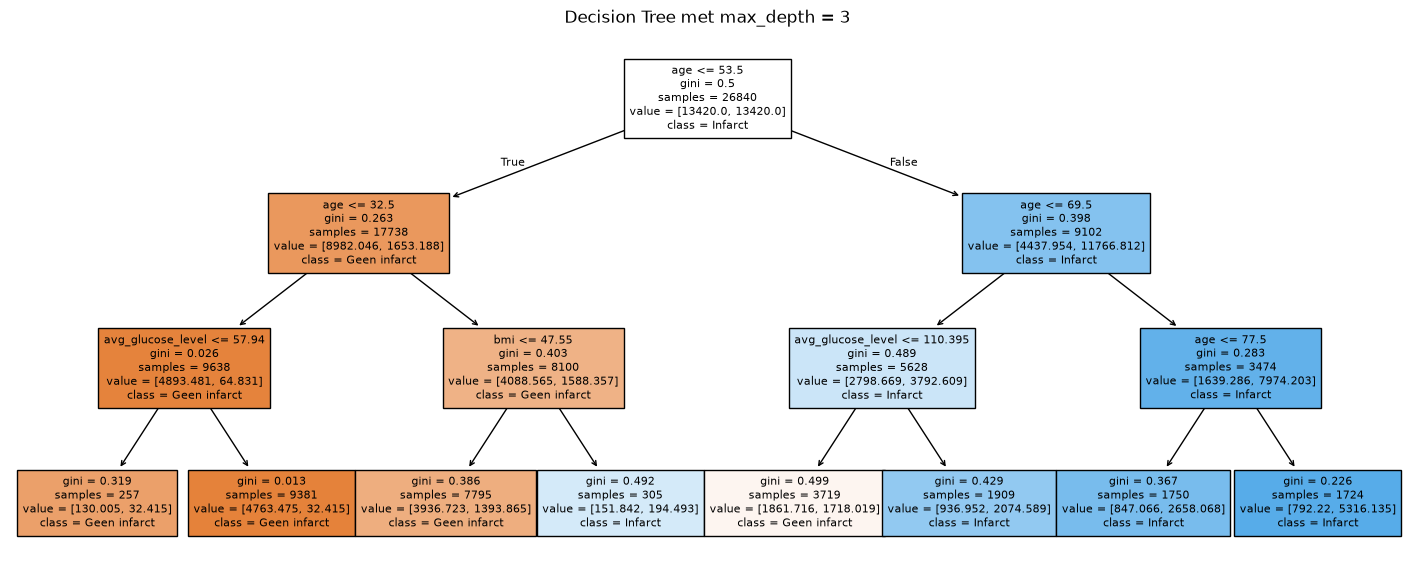

In [19]:
kleine_boom = DecisionTreeClassifier(max_depth=3, class_weight='balanced', random_state=42)
kleine_boom.fit(X_train_dt, y_train_dt)

plt.figure(figsize=(18, 7))
plot_tree(kleine_boom, feature_names=list(X_train_dt.columns), class_names=['Geen infarct', 'Infarct'],
          filled=True, fontsize=8)
plt.title('Decision Tree met max_depth = 3')
plt.show()

### Hyperparameter tuning

We zoeken met `GridSearchCV` (5-voudige cross-validation, scoring = F1 van klasse 1) de beste combinatie van:
* `criterion`: Gini of entropie
* `max_depth` en `min_samples_leaf` (pre-pruning)
* `ccp_alpha` (post-pruning)
* de techniek tegen onbalans: SMOTE, class weights of allebei

In [20]:
# 1. Pipeline: eerst SMOTE (alleen op de trainingsfolds), daarna de boom
tree_pipeline = Pipeline([
    ('smote', SMOTE(random_state=42)),
    ('tree', DecisionTreeClassifier(random_state=42))
])

# 2. De hyperparameters van de boom (pre- en post-pruning)
boom_parameters = {
    'tree__criterion': ['gini', 'entropy'],
    'tree__max_depth': [3, 5, 8, None],
    'tree__min_samples_leaf': [5, 20, 50],
    'tree__ccp_alpha': [0, 0.001, 0.005]
}

# 3. De technieken tegen onbalans: SMOTE alleen, class weights alleen en allebei
param_grid_tree = [
    {'smote': [SMOTE(random_state=42)], 'tree__class_weight': [None], **boom_parameters},
    {'smote': ['passthrough'], 'tree__class_weight': ['balanced'], **boom_parameters},
    {'smote': [SMOTE(random_state=42)], 'tree__class_weight': ['balanced'], **boom_parameters},
]

# 4. Cross-validation instellen. We kijken specifiek naar de f1-score.
cv_tree = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid_tree = GridSearchCV(tree_pipeline, param_grid_tree, cv=cv_tree, scoring='f1', n_jobs=-1)

# 5. Model trainen
print("Bezig met trainen en hyperparameter tuning voor de Decision Tree...")
grid_tree.fit(X_train_dt, y_train_dt)

# 6. Uitkomsten printen
print("\nBeste hyperparameters voor de Decision Tree:")
for naam, waarde in grid_tree.best_params_.items():
    print(f"  {naam}: {waarde}")
print("Beste F1-score uit cross-validation:", round(grid_tree.best_score_, 4))

Bezig met trainen en hyperparameter tuning voor de Decision Tree...

Beste hyperparameters voor de Decision Tree:
  smote: SMOTE(random_state=42)
  tree__ccp_alpha: 0
  tree__class_weight: None
  tree__criterion: gini
  tree__max_depth: 8
  tree__min_samples_leaf: 5
Beste F1-score uit cross-validation: 0.1332


Confusion Matrix:


,Voorspeld: 0,Voorspeld: 1
Werkelijk: 0,6284,323
Werkelijk: 1,84,19



Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.95      0.97      6607
           1       0.06      0.18      0.09       103

    accuracy                           0.94      6710
   macro avg       0.52      0.57      0.53      6710
weighted avg       0.97      0.94      0.96      6710

F1-score klasse 1 op de validatieset: 0.0854


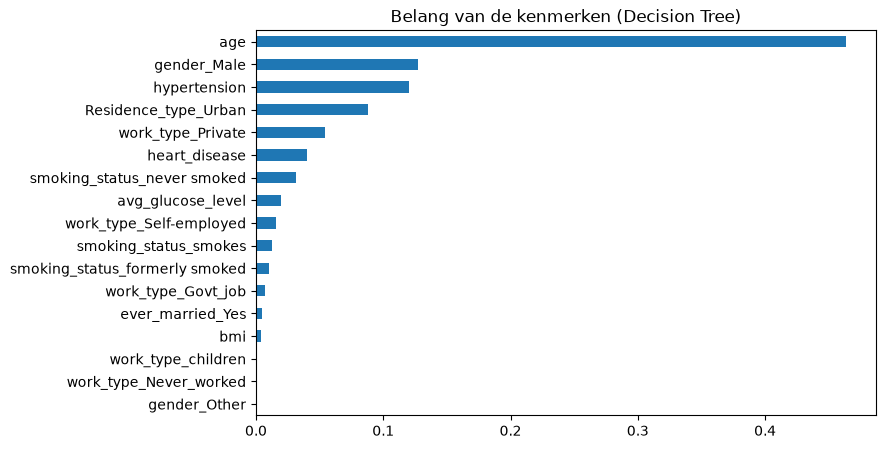

In [21]:
# Controleer het beste model op de validatieset die het model nog nooit gezien heeft
beste_boom = grid_tree.best_estimator_
y_pred_tree = beste_boom.predict(X_valid_dt)

print("Confusion Matrix:")
cm_tree = confusion_matrix(y_valid_dt, y_pred_tree)
display(pd.DataFrame(cm_tree, index=['Werkelijk: 0', 'Werkelijk: 1'],
                     columns=['Voorspeld: 0', 'Voorspeld: 1']))

print("\nClassification Report:")
print(classification_report(y_valid_dt, y_pred_tree, zero_division=0))
print("F1-score klasse 1 op de validatieset:", round(f1_score(y_valid_dt, y_pred_tree), 4))

# Welke kenmerken gebruikt de boom het meest?
belang = pd.Series(beste_boom.named_steps['tree'].feature_importances_, index=X_train_dt.columns)
belang.sort_values().plot(kind='barh', figsize=(8, 5), title='Belang van de kenmerken (Decision Tree)')
plt.show()

### **Resultaat van Decision Tree**
Uit de GridSearchCV blijken de volgende hyperparameters de beste resultaten te geven:
* Techniek tegen onbalans: alleen SMOTE (geen class weights)
* Splitscriterium (`criterion`): Gini
* Maximale diepte (`max_depth`): 8 (pre-pruning)
* Minimaal aantal patiënten per blad (`min_samples_leaf`): 5 (pre-pruning)
* Cost-complexity pruning (`ccp_alpha`): 0, dus geen post-pruning

Met deze instellingen behaalt het model een F1-score van **0,1332** in de cross-validation. Op de validatieset is de F1-score **0,0854** (precision 0,06 en recall 0,18). Van de 103 patiënten met een herseninfarct vindt de boom er 19 (TP) en mist hij er 84 (FN). Daar staan 323 patiënten zonder infarct tegenover die onterecht zijn gemarkeerd (FP).

**Wat valt op?**
* **De boom gebruikt vooral pre-pruning.** De GridSearch kiest een beperkte diepte (8) en minimaal 5 patiënten per blad, maar geen post-pruning. In de grafiek hierboven (zonder SMOTE) lag het optimum voor `ccp_alpha` rond 0,0005, een waarde die niet in onze grid zat (0, 0,001 en 0,005). Het team kan de grid uitbreiden om te testen of dat de score verbetert.
* **SMOTE alleen werkte beter dan class weights of allebei.** Een boom met class weights telt de zeldzame patiënten zwaarder mee bij elke splitsing, maar SMOTE geeft de boom meer (synthetische) voorbeelden om in te splitsen.
* **Het verschil tussen cross-validation (0,133) en validatie (0,085) is groot.** Een deel komt door het tunen op dezelfde folds (optimistisch), en een deel is toeval, want de validatieset bevat maar 103 patiënten met een infarct. Een paar extra treffers verandert de F1 al met ongeveer 0,01.
* **De boom is voorzichtig.** Hij markeert 342 patiënten als risico en vindt er 19 van de 103. LR en SVM markeren er veel meer en hebben daardoor een veel hogere recall, maar ook veel meer valse alarmen. De F1-scores liggen dicht bij elkaar (rond 0,09–0,10).
* **Leeftijd is het belangrijkste kenmerk** (belang ongeveer 0,46), wat past bij de EDA. Opvallend is dat `gender_Male`, `hypertension` en `Residence_type_Urban` daarna komen, terwijl woonomgeving en geslacht in de EDA nauwelijks samenhingen met een infarct en glucose juist weinig belang krijgt. Dat kan komen doordat een diepe boom op SMOTE-data ook ruis meeneemt. Interpreteer het belang van deze kenmerken dus voorzichtig.

**Voorspellingen voor Kaggle**

We trainen het beste model opnieuw op alle trainingsdata en voorspellen `test_ml.csv`. Omdat een boom niet standaardiseert, kunnen we de ruwe testdata direct gebruiken (met dezelfde kolommen als bij de training).

In [22]:
# 1. Beste model opnieuw trainen op alle trainingsdata
final_tree = grid_tree.best_estimator_
final_tree.fit(X_full_dt, y_full_dt)

# 2. Voorspellen voor de Kaggle-testdata
voorspelling_tree = final_tree.predict(X_kaggle_dt)

# 3. Opslaan in het formaat van sample_submission.csv
submission_tree = pd.read_csv('sample_submission.csv')
submission_tree['stroke'] = voorspelling_tree
submission_tree.to_csv('submission_decision_tree.csv', index=False)

print("Aantal voorspelde herseninfarcten:", int(voorspelling_tree.sum()), "van", len(voorspelling_tree))
submission_tree.head()

Aantal voorspelde herseninfarcten: 210 van 8388


,id,stroke
0,32840,0
1,45158,0
2,56105,0
3,3112,0
4,35224,0


# Ensembles: Random Forest, Gradient Boosted Decision Trees en XGBoost

Een **ensemble** combineert veel zwakke modellen (hier: beslisbomen) tot één sterk
model. Eén losse beslisboom overfit snel: hij groeit door tot elk blad bijna puur is
en leert daarmee de ruis van de trainingsdata uit het hoofd. Door veel bomen te
combineren middelen die fouten grotendeels tegen elkaar weg.

Er zijn twee manieren om die bomen te combineren: **bagging** en **boosting**.

---

## 1. Random Forest — bagging (bootstrap aggregation)

Random Forest werkt met **bagging**, de afkorting van *bootstrap aggregation*. Dat
zijn letterlijk twee stappen:

**Bootstrap.** Voor elke boom wordt een willekeurige steekproef *met teruglegging*
uit de trainingsdata getrokken, even groot als de originele dataset. Doordat er
teruglegging is, komen sommige patiënten meerdere keren voor en andere helemaal
niet (gemiddeld blijft ongeveer 37% van de rijen ongebruikt, de *out-of-bag*
steekproef). Elke boom ziet dus een net iets andere dataset en maakt daardoor
andere fouten.

**Aggregation.** Alle bomen stemmen over de uitkomst. Bij classificatie wordt de
meerderheid genomen, of het gemiddelde van de voorspelde kansen.

Random Forest voegt daar nog een tweede vorm van toeval aan toe: bij elke splitsing
mag de boom maar uit een willekeurige deelverzameling van de variabelen kiezen
(`max_features`). Zonder die truc zouden alle bomen bovenin dezelfde dominante
variabele kiezen — bij deze dataset waarschijnlijk `age` — en sterk op elkaar
lijken. Juist de onderlinge verschillen maken het gemiddelde betrouwbaar.

**Belangrijk:** de bomen hebben elkaar niet nodig. Boom 50 weet niets van boom 49.
Ze kunnen daarom **parallel** getraind worden, over alle processorkernen tegelijk
(`n_jobs=-1`). Random Forest is om die reden relatief snel.

---

## 2. Gradient Boosted Decision Trees — boosting

Boosting werkt precies andersom. In plaats van veel onafhankelijke bomen te middelen,
worden de bomen **sequentieel** gebouwd: elke nieuwe boom probeert de fouten van het
model tot dan toe te corrigeren.

Het verloop:

1. Begin met een simpele voorspelling (bijvoorbeeld het gemiddelde).
2. Bereken waar het model ernaast zit — de *residuen*, oftewel de gradiënt van de
   verliesfunctie.
3. Train een kleine boom die juist die fouten voorspelt.
4. Tel die boom bij het model op, maar slechts voor een klein deel ervan: de
   **learning rate**.
5. Herhaal.

De learning rate $$\eta$$ bepaalt hoe groot elke correctiestap is:

$$F_{m}(x) = F_{m-1}(x) + \eta \cdot h_m(x)$$

Een lage $$\eta$$ betekent kleine, voorzichtige stappen en dus minder overfitting,
maar je hebt er wel meer bomen voor nodig. Dat is de belangrijkste afweging bij dit
model: `learning_rate` en `n_estimators` moet je altijd samen tunen.

De bomen zijn hier bewust **ondiep** (`max_depth` 2 of 3). Elke boom hoeft maar een
klein stukje van het probleem op te lossen; de kracht zit in de optelsom van
honderden zwakke correcties.

**Belangrijk:** boom $$m$$ kan pas gebouwd worden als boom $$m-1$$ klaar is, want
hij heeft de resterende fouten nodig. Dit proces is dus inherent **sequential** en
kan niet over kernen verdeeld worden. Daarom is `GradientBoostingClassifier` van
scikit-learn veruit de traagste van de drie.

---

## 3. XGBoost — boosting, maar dan geoptimaliseerd

XGBoost (*eXtreme Gradient Boosting*) gebruikt hetzelfde boosting-principe, maar is
op drie punten slimmer gebouwd:

- **Histogram-based splitsingen** (`tree_method='hist'`). In plaats van elke mogelijke
  drempelwaarde van een variabele te proberen, worden de waarden eerst in ~256 bakjes
  verdeeld. Dat scheelt enorm veel rekenwerk bij 33.550 rijen.
- **Parallellisatie bínnen een boom.** De volgorde van de bomen blijft sequentieel,
  maar het zoeken naar de beste splitsing wordt wél over alle kernen verdeeld.
- **Ingebouwde regularisatie.** XGBoost straft complexiteit expliciet af via termen
  in de verliesfunctie (`lambda`, `alpha`, `gamma`), waar klassieke GBDT dat alleen
  indirect doet via de boomdiepte.

Daarmee combineert XGBoost de nauwkeurigheid van boosting met een trainingstijd die
veel dichter bij Random Forest ligt.

---

## Trainingstijd samengevat

| Ensemble | Techniek | Bomen bouwen | Trainingstijd |
|---|---|---|---|
| Random Forest | bagging | **parallel**, volledig onafhankelijk | kort |
| Gradient Boosting (sklearn) | boosting | **sequential**, strikt één voor één | lang |
| XGBoost | boosting | sequentieel, maar parallel *binnen* elke boom | middel |

De kern van het verschil: bij bagging bestaat er geen volgorde, dus kun je alles
tegelijk doen. Bij boosting bestaat de volgorde juist wél en is die essentieel,
want elke boom corrigeert zijn voorganger. Dat maakt boosting principieel
langzamer — XGBoost verzacht dat met technische optimalisaties, maar heft het
niet op.

Het script meet de tijd per grid search met `time.perf_counter()`, zodat je deze
tabel met je eigen meetwaarden kunt onderbouwen in plaats van met een aanname.
Vergelijk daarbij ook het aantal fits: een grid met meer combinaties kost
vanzelfsprekend meer tijd, dus kijk naar de tijd *per fit* voor een eerlijke
vergelijking.

---

## Omgaan met de imbalanced dataset

Bij alle drie de ensembles is **SMOTE** in de pipeline opgenomen, zodat de
oversampling per fold gebeurt en niet lekt naar de validatieset. Beide
boom-ensembles hebben daarnaast een ingebouwd alternatief dat je kunt vergelijken:

- Random Forest: `class_weight='balanced'` of `'balanced_subsample'`
- XGBoost: `scale_pos_weight = aantal negatieven / aantal positieven`

Die laatste laat fouten op de minderheidsklasse zwaarder meewegen in de
verliesfunctie, zonder dat er kunstmatige datapunten bij worden verzonnen. Dat is
een tweede, volwaardige imbalance-techniek die je naast SMOTE kunt rapporteren.

---

## Waarom hier geen StandardScaler?

Bij KNN was standaardisatie cruciaal, omdat dat model met afstanden rekent. Een
beslisboom doet dat niet: die zoekt drempelwaarden ("is `age` > 67?"). Of leeftijd
nu in jaren of in maanden staat, de volgorde van de patiënten verandert niet en de
splitsing blijft dezelfde. Schalen heeft bij bomen dus geen enkel effect — weglaten
scheelt alleen rekentijd.

In [42]:
%pip install xgboost
import time
import pandas as pd
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.metrics import confusion_matrix, classification_report

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---- ----------------------------------- 5.2/48.9 MB 42.4 MB/s eta 0:00:02
   --------- ------------------------------ 11.3/48.9 MB 36.7 MB/s eta 0:00:02
   --------- ------------------------------ 12.1/48.9 MB 23.1 MB/s eta 0:00:02
   ---------- ----------------------------- 12.8/48.9 MB 18.1 MB/s eta 0:00:02
   ----------- ---------------------------- 13.6/48.9 MB 14.9 MB/s eta 0:00:03
   ----------- ---------------------------- 14.4/48.9 MB 12.7 MB/s eta 0:00:03
   ------------ --------------------------- 15.5/48.9 MB 11.2 MB/s eta 0:00:03
   ------------- -------------------------- 16.3/48.9 MB 10.2 MB/s eta 0:00:04
   ------------- -------------------------- 17.0/48.9 MB 9.6 MB/s eta 0:00:04
   -------------- ------------------------- 17.8/48.9 MB 8.9 MB/s eta 0:00:04
   --------------- ------------------------ 18.6/48.9 MB 8.6 MB/s eta 0:00:04
   --------------- ------------------------ 19.4/48.9 MB 8.2 MB/s


[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [49]:

# ---------------------------------------------------------------
# 0. Split (zelfde namen als bij de andere modellen: X_hold = holdout)
# ---------------------------------------------------------------
X = df.drop(columns=['stroke'])
y = df['stroke']

X_train, X_hold, y_train, y_hold = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Hierin bewaren we per model de resultaten voor de vergelijkingstabel
resultaten = []


def tune(naam, pipeline, param_grid, n_jobs=-1):
    """Tunet een model, print de uitkomsten en meet de trainingstijd."""
    grid = GridSearchCV(pipeline, param_grid, cv=cv, scoring='f1', n_jobs=n_jobs)

    print(f"\n=== {naam} ===")
    start = time.perf_counter()
    grid.fit(X_train, y_train)
    duur = time.perf_counter() - start

    print("Beste hyperparameters:", grid.best_params_)
    print("Beste F1-score (CV):", round(grid.best_score_, 4))
    print(f"Trainingstijd hele grid search: {duur:.1f} seconden")

    resultaten.append({
        'model': naam,
        'f1_cv': round(grid.best_score_, 4),
        'tijd_sec': round(duur, 1),
        'aantal_fits': len(grid.cv_results_['params']) * cv.get_n_splits(),
        'beste_params': grid.best_params_
    })
    return grid


In [40]:
# ---------------------------------------------------------------
# 1. RANDOM FOREST  (bagging, parallel -> relatief snel)
# ---------------------------------------------------------------
rf_pipeline = Pipeline([
    ('smote', SMOTE(random_state=42)),
    ('rf', RandomForestClassifier(random_state=42, n_jobs=-1))
])

param_grid_rf = {
    'rf__n_estimators': [200, 400],
    'rf__max_depth': [None, 10, 20],
    'rf__min_samples_leaf': [1, 5],
    'rf__max_features': ['sqrt', 0.5]
}

# n_jobs=1 in de grid, want de RF gebruikt zelf al alle cores
grid_rf = tune("Random Forest", rf_pipeline, param_grid_rf, n_jobs=1)




=== Random Forest ===
Beste hyperparameters: {'rf__max_depth': 10, 'rf__max_features': 0.5, 'rf__min_samples_leaf': 5, 'rf__n_estimators': 200}
Beste F1-score (CV): 0.0951
Trainingstijd hele grid search: 256.9 seconden


In [41]:

# ---------------------------------------------------------------
# 2. GRADIENT BOOSTED DECISION TREES  (boosting, sequential -> traag)
# ---------------------------------------------------------------
gb_pipeline = Pipeline([
    ('smote', SMOTE(random_state=42)),
    ('gb', GradientBoostingClassifier(random_state=42))
])

# Bewust een kleine grid: dit model is sequentieel en dus langzaam.
param_grid_gb = {
    'gb__n_estimators': [100, 200],
    'gb__learning_rate': [0.05, 0.1],
    'gb__max_depth': [2, 3]
}

grid_gb = tune("Gradient Boosting (sklearn)", gb_pipeline, param_grid_gb)


=== Gradient Boosting (sklearn) ===
Beste hyperparameters: {'gb__learning_rate': 0.05, 'gb__max_depth': 3, 'gb__n_estimators': 100}
Beste F1-score (CV): 0.0929
Trainingstijd hele grid search: 53.0 seconden


In [43]:


# ---------------------------------------------------------------
# 3. XGBOOST  (boosting, maar geoptimaliseerd -> veel sneller dan 2)
# ---------------------------------------------------------------
from xgboost import XGBClassifier

xgb_pipeline = Pipeline([
    ('smote', SMOTE(random_state=42)),
    ('xgb', XGBClassifier(
        random_state=42,
        eval_metric='logloss',
        tree_method='hist',   # histogram-based: dit maakt XGBoost snel
        n_jobs=-1
    ))
])

param_grid_xgb = {
    'xgb__n_estimators': [200, 400],
    'xgb__learning_rate': [0.05, 0.1],
    'xgb__max_depth': [3, 5],
    'xgb__subsample': [0.8, 1.0]
}

grid_xgb = tune("XGBoost", xgb_pipeline, param_grid_xgb, n_jobs=1)


=== XGBoost ===
Beste hyperparameters: {'xgb__learning_rate': 0.1, 'xgb__max_depth': 3, 'xgb__n_estimators': 400, 'xgb__subsample': 1.0}
Beste F1-score (CV): 0.103
Trainingstijd hele grid search: 81.2 seconden


In [44]:
# ---------------------------------------------------------------
# 4. Vergelijkingstabel (direct bruikbaar in je verslag)
# ---------------------------------------------------------------
print("\n=== Vergelijking ensembles ===")
print(pd.DataFrame(resultaten)[['model', 'f1_cv', 'tijd_sec', 'aantal_fits']])


=== Vergelijking ensembles ===
                         model   f1_cv  tijd_sec  aantal_fits
0                Random Forest  0.0951     256.9          120
1  Gradient Boosting (sklearn)  0.0929      53.0           40
2                      XGBoost  0.1030      81.2           80


In [45]:
# ---------------------------------------------------------------
# 5. Welke variabelen wegen het zwaarst? (feature importance)
# ---------------------------------------------------------------
for naam, grid, stap in [("Random Forest", grid_rf, 'rf'),
                         ("Gradient Boosting", grid_gb, 'gb'),
                         ("XGBoost", grid_xgb, 'xgb')]:
    model = grid.best_estimator_.named_steps[stap]
    imp = pd.Series(model.feature_importances_, index=X_train.columns)
    print(f"\nBelangrijkste features volgens {naam}:")
    print(imp.sort_values(ascending=False).head(8).round(3))


Belangrijkste features volgens Random Forest:
age                            0.609
ever_married_Yes               0.093
avg_glucose_level              0.076
bmi                            0.057
Residence_type_Urban           0.024
gender_Male                    0.023
smoking_status_never smoked    0.021
work_type_Self-employed        0.017
dtype: float64

Belangrijkste features volgens Gradient Boosting:
age                            0.885
ever_married_Yes               0.020
avg_glucose_level              0.018
Residence_type_Urban           0.018
gender_Male                    0.018
smoking_status_never smoked    0.014
smoking_status_smokes          0.009
bmi                            0.007
dtype: float64

Belangrijkste features volgens XGBoost:
ever_married_Yes                  0.239
age                               0.150
Residence_type_Urban              0.102
smoking_status_never smoked       0.070
gender_Male                       0.068
smoking_status_smokes             0.059

In [46]:
# ---------------------------------------------------------------
# 6. Evalueren op de holdout, net als bij het basismodel
# ---------------------------------------------------------------
for naam, grid in [("Random Forest", grid_rf),
                   ("Gradient Boosting", grid_gb),
                   ("XGBoost", grid_xgb)]:
    y_pred = grid.predict(X_hold)
    print(f"\n--- {naam}: confusion matrix op holdout ---")
    cm = pd.DataFrame(
        confusion_matrix(y_hold, y_pred),
        index=['Werkelijk: 0', 'Werkelijk: 1'],
        columns=['Voorspeld: 0', 'Voorspeld: 1']
    )
    print(cm)
    print(classification_report(y_hold, y_pred, zero_division=0))


--- Random Forest: confusion matrix op holdout ---
              Voorspeld: 0  Voorspeld: 1
Werkelijk: 0          5570          1037
Werkelijk: 1            50            53
              precision    recall  f1-score   support

           0       0.99      0.84      0.91      6607
           1       0.05      0.51      0.09       103

    accuracy                           0.84      6710
   macro avg       0.52      0.68      0.50      6710
weighted avg       0.98      0.84      0.90      6710


--- Gradient Boosting: confusion matrix op holdout ---
              Voorspeld: 0  Voorspeld: 1
Werkelijk: 0          5327          1280
Werkelijk: 1            40            63
              precision    recall  f1-score   support

           0       0.99      0.81      0.89      6607
           1       0.05      0.61      0.09       103

    accuracy                           0.80      6710
   macro avg       0.52      0.71      0.49      6710
weighted avg       0.98      0.80      0.88    

In [48]:
# ---------------------------------------------------------------
# 7. Submission maken met het beste ensemble
# ---------------------------------------------------------------
beste = max(resultaten, key=lambda r: r['f1_cv'])
print("\nBeste ensemble:", beste['model'])

beste_grid = {'Random Forest': grid_rf,
              'Gradient Boosting (sklearn)': grid_gb,
              'XGBoost': grid_xgb}[beste['model']]

df_test = pd.read_csv('test_ml.csv')
ids = df_test['id']

# Zelfde voorbewerking als bij df! Pas deze regel aan als jij het anders deed.
X_kaggle = pd.get_dummies(df_test.drop(columns=['id']), drop_first=True)
X_kaggle = X_kaggle.reindex(columns=X_train.columns, fill_value=0)
assert list(X_kaggle.columns) == list(X_train.columns), "Kolommen komen niet overeen!"

submission = pd.DataFrame({'id': ids, 'stroke': beste_grid.predict(X_kaggle)})
submission.to_csv('submission_ensemble.csv', index=False)
print("submission_ensemble.csv opgeslagen:", submission.shape)


Beste ensemble: XGBoost
submission_ensemble.csv opgeslagen: (8388, 2)


# Zelf samengesteld ensemble

## Hoe werkt een ensemble?

Een ensemble is geen nieuw algoritme, maar een **samenwerkingsvorm**: je laat
meerdere modellen afzonderlijk een voorspelling doen en combineert die tot één
eindoordeel. De vergelijking is een adviescommissie: drie specialisten kijken
ieder op hun eigen manier naar dezelfde patiënt en samen nemen ze een besluit.

Dit werkt alleen onder één voorwaarde: de modellen moeten **verschillende
fouten** maken. Maken ze allemaal dezelfde fout, dan versterkt het ensemble die
fout alleen maar. Wijken hun fouten van elkaar af, dan vallen ze tegen elkaar
weg en blijft het signaal over dat ze wél delen. Dit heet het bias-variance
voordeel van ensembles: de variantie (de toevallige fouten van één model) daalt,
terwijl het systematische deel van de voorspelling behouden blijft.

Random Forest is hier zelf al een voorbeeld van, maar daar bestaan alle leden
uit hetzelfde type model (beslisbomen). In een zelf samengesteld ensemble
combineer je juist **verschillende soorten** modellen. Dat heet een
*heterogeen* ensemble en de onderlinge verschillen zijn er daardoor groter.

## Welke vorm van voting en waarom?

Er zijn twee vormen:

**Hard voting** — ieder model geeft een hard label (0 of 1) en de meerderheid
wint. Stemmen twee van de drie modellen op "infarct", dan is de uitkomst 1.
Nadeel: alle informatie over *hoe zeker* een model is, gaat verloren. Een model
dat 0,51 zegt telt even zwaar als een model dat 0,99 zegt.

**Soft voting** — ieder model geeft een kans en die kansen worden gemiddeld:

$$\hat{p} = \frac{1}{\sum_i w_i}\sum_{i} w_i \, p_i$$

Daarbij is $$p_i$$ de voorspelde kans van model $$i$$ en $$w_i$$ het gewicht van
dat model. Pas daarna wordt op de drempel van 0,5 afgerond naar 0 of 1.

**Ik heb gekozen voor soft voting.** De reden is de imbalanced dataset: bij een
klasse die maar in enkele procenten van de gevallen voorkomt, zijn de voorspelde
kansen voor "infarct" vaak laag en liggen ze dicht bij de drempel. Juist dan is
het verschil tussen 0,45 en 0,49 betekenisvol. Hard voting gooit dat verschil
weg en maakt het ensemble onnodig grof. Bovendien kan één zeer zeker model bij
soft voting twee twijfelende modellen overstemmen, wat bij hard voting
onmogelijk is. In de grid search zijn beide vormen getest, zodat de keuze ook
met een meetresultaat onderbouwd is.

Voorwaarde voor soft voting is dat elk model `predict_proba` ondersteunt. KNN,
Logistic Regression en Random Forest doen dat alle drie.

## Waarom juist deze drie modellen?

Het selectiecriterium was **diversiteit**: drie modellen die op fundamenteel
verschillende manieren tot een beslissing komen.

| Model | Manier van beslissen | Wat het goed kan | Zwakte |
|---|---|---|---|
| **K-Nearest Neighbors** | afstand tot vergelijkbare patiënten | lokale patronen, geen aanname over de vorm | gevoelig voor ruis en voor veel features |
| **Logistic Regression** | één lineaire scheidslijn over alle data | stabiel, weinig variantie, goed te interpreteren | mist niet-lineaire verbanden |
| **Random Forest** | opeenvolgende splitsingen op drempelwaarden | interacties tussen variabelen, niet-lineair | kan overfitten, weinig inzicht in de vorm van het verband |

De drie vullen elkaar aan op precies de punten waar ze tekortschieten. KNN
oordeelt **lokaal** (alleen de buurt telt), Logistic Regression **globaal** (één
formule voor iedereen) en Random Forest zit daartussenin met gebiedsgewijze
regels. Een patiënt die door de lineaire scheidslijn verkeerd wordt ingedeeld,
kan door zijn buren alsnog correct worden geclassificeerd en omgekeerd.

Een praktisch argument komt erbij: alle drie leveren kansen en alle drie zijn
snel genoeg om binnen een grid search meerdere keren te trainen.

## Omgaan met de imbalanced dataset

Elk lid van het ensemble heeft zijn **eigen SMOTE-stap** in de pipeline. Dat is
bewust: SMOTE wordt zo per cross-validation fold opnieuw toegepast, en alleen op
het trainingsdeel. Zou je vooraf één keer over de hele dataset resamplen, dan
belanden synthetische punten ook in de validatiefold en meet je een te
optimistische score (data leakage).

De tweede techniek zit in de gewichten en de voting zelf: door het gewicht van
een model te verhogen, verschuif je in feite de beslisgrens van het ensemble,
wat vergelijkbaar werkt met het aanpassen van de drempelwaarde.

## Gekozen metric

De F1-score op klasse 1, net als bij de overige modellen. Accuracy is hier
onbruikbaar: een model dat iedereen gezond verklaart haalt al ruim 95%. F1 weegt
precision en recall tegen elkaar af en straft dus zowel gemiste infarcten als
vals alarm.



In [51]:
import time
import pandas as pd
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import confusion_matrix, classification_report

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)


In [52]:
# ---------------------------------------------------------------
# 1. De drie bouwstenen (members) van het ensemble
#    Vul hier de beste hyperparameters in die je eerder hebt gevonden.
# ---------------------------------------------------------------

# Model 1: KNN -> kijkt naar de afstand tot de buren (niet-lineair, lokaal)
knn_member = Pipeline([
    ('scaler', StandardScaler()),          # bij KNN verplicht: afstand
    ('smote', SMOTE(random_state=42)),
    ('knn', KNeighborsClassifier(n_neighbors=11, weights='distance'))
])

# Model 2: Logistic Regression -> trekt 1 rechte scheidslijn (lineair, globaal)
logreg_member = Pipeline([
    ('scaler', StandardScaler()),          # nodig voor eerlijke regularisatie
    ('smote', SMOTE(random_state=42)),
    ('logreg', LogisticRegression(solver='liblinear', C=1, penalty='l2',
                                  max_iter=1000, random_state=42))
])

# Model 3: Random Forest -> splitst op drempelwaardes, vangt interacties
rf_member = Pipeline([
    ('smote', SMOTE(random_state=42)),     # bomen hebben geen scaler nodig
    ('rf', RandomForestClassifier(n_estimators=300, max_depth=10,
                                  min_samples_leaf=5,
                                  random_state=42, n_jobs=-1))
])



In [53]:

# ---------------------------------------------------------------
# 2. Het ensemble zelf
#    voting='soft' -> gemiddelde van de kansen (standaardkeuze, zie verslag)
# ---------------------------------------------------------------
voting_ensemble = VotingClassifier(
    estimators=[
        ('knn', knn_member),
        ('logreg', logreg_member),
        ('rf', rf_member)
    ],
    voting='soft',
    n_jobs=-1
)

In [54]:
# ---------------------------------------------------------------
# 3. Hyperparameters van het ENSEMBLE: de vorm van voting + de gewichten
#    Een gewicht zegt: hoe zwaar telt de stem van dit model mee?
# ---------------------------------------------------------------
param_grid_vote = {
    'voting': ['soft', 'hard'],
    'weights': [
        [1, 1, 1],   # alle modellen even zwaar
        [1, 1, 2],   # RF telt dubbel
        [1, 2, 1],   # LogReg telt dubbel
        [2, 1, 1],   # KNN telt dubbel
        [1, 2, 3],   # oplopend vertrouwen
    ]
}
grid_vote = GridSearchCV(
    voting_ensemble,
    param_grid_vote,
    cv=cv,
    scoring='f1',
    n_jobs=1          # de members draaien zelf al parallel
)

print("Bezig met trainen en tunen van het zelf samengestelde ensemble...")
start = time.perf_counter()
grid_vote.fit(X_train, y_train)
duur = time.perf_counter() - start

print("\nBeste hyperparameters ensemble:", grid_vote.best_params_)
print("Beste F1-score uit cross-validation:", round(grid_vote.best_score_, 4))
print("Trainingstijd (sec):", round(duur, 1))

Bezig met trainen en tunen van het zelf samengestelde ensemble...

Beste hyperparameters ensemble: {'voting': 'soft', 'weights': [1, 1, 1]}
Beste F1-score uit cross-validation: 0.1119
Trainingstijd (sec): 131.6


In [55]:
# ---------------------------------------------------------------
# 4. Hoe goed is het ensemble t.o.v. de losse modellen?
#    (bewijs dat samenwerken loont -> direct bruikbaar in je verslag)
# ---------------------------------------------------------------
from sklearn.model_selection import cross_val_score

print("\n=== Los model vs. ensemble (F1, 5-fold CV) ===")
vergelijking = []
for naam, model in [('KNN', knn_member),
                    ('Logistic Regression', logreg_member),
                    ('Random Forest', rf_member)]:
    score = cross_val_score(model, X_train, y_train, cv=cv,
                            scoring='f1', n_jobs=-1).mean()
    vergelijking.append({'model': naam, 'f1_cv': round(score, 4)})

vergelijking.append({'model': 'Voting ensemble', 'f1_cv': round(grid_vote.best_score_, 4)})
print(pd.DataFrame(vergelijking))



=== Los model vs. ensemble (F1, 5-fold CV) ===
                 model   f1_cv
0                  KNN  0.0794
1  Logistic Regression  0.0901
2        Random Forest  0.0921
3      Voting ensemble  0.1119


In [56]:
# ---------------------------------------------------------------
# 5. Evalueren op de holdout, net als bij de andere modellen
# ---------------------------------------------------------------
y_pred_vote = grid_vote.predict(X_hold)

print("\nConfusion Matrix (voting ensemble):")
cm = pd.DataFrame(
    confusion_matrix(y_hold, y_pred_vote),
    index=['Werkelijk: 0', 'Werkelijk: 1'],
    columns=['Voorspeld: 0', 'Voorspeld: 1']
)
print(cm)

print("\nClassification Report (voting ensemble):")
print(classification_report(y_hold, y_pred_vote, zero_division=0))


Confusion Matrix (voting ensemble):
              Voorspeld: 0  Voorspeld: 1
Werkelijk: 0          5704           903
Werkelijk: 1            54            49

Classification Report (voting ensemble):
              precision    recall  f1-score   support

           0       0.99      0.86      0.92      6607
           1       0.05      0.48      0.09       103

    accuracy                           0.86      6710
   macro avg       0.52      0.67      0.51      6710
weighted avg       0.98      0.86      0.91      6710



In [58]:
# ---------------------------------------------------------------
# 6. Submission maken
# ---------------------------------------------------------------
df_test = pd.read_csv('test_ml.csv')
ids = df_test['id']

# Zelfde voorbewerking als bij df! Pas deze regel aan als jij het anders deed.
X_kaggle = pd.get_dummies(df_test.drop(columns=['id']), drop_first=True)
X_kaggle = X_kaggle.reindex(columns=X_train.columns, fill_value=0)
assert list(X_kaggle.columns) == list(X_train.columns), "Kolommen komen niet overeen!"

submission = pd.DataFrame({'id': ids, 'stroke': grid_vote.predict(X_kaggle)})
submission.to_csv('submission_voting.csv', index=False)
print("\nsubmission_voting.csv opgeslagen:", submission.shape)


submission_voting.csv opgeslagen: (8388, 2)


## Resultaten

| Model | Beste F1 (5-fold CV) |
|---|---|
| KNN | *0.0794* |
| Logistic Regression | *0.0901* |
| Random Forest | *0.0921* |
| **Voting ensemble** | *0.1119* |

**Beste hyperparameters:** `voting = soft`, `weights = [1, 1, 1]`

### Interpretatie

Het ensemble model heeft duidelijk een betere uitkomst. 